# E12 · Laboratorio integrado · Grupo 1 · Ruta agroambiental

Notebook integrado del grupo 1, construido sobre la [plantilla E12](../ejercicios/E12_pipeline_plantilla.ipynb): conserva sus nueve secciones y el texto de cada una, y debajo desarrolla la respuesta del equipo. Reúne en un solo recorrido los cuatro notebooks por capa (`soluciones/grupo_1/G1_01_raw`, `G1_02_silver`, `G1_03_gold` y `G1_04_presentacion_completo`) sin repetir código: rutas, entorno, huellas, firmas, contratos, registro y antiduplicidad se definen una vez en la sección 2, y cada capa es una función que se aplica en la sección que le corresponde. Consulta el [enunciado E12](../talleres/E12.md) y la [solución docente](E12_solucion.ipynb).

**Pregunta:** ¿qué cultivos tienen mejor rendimiento por municipio y año?

**Unidad de observación:** una fila de la Evaluación Agropecuaria Municipal (EVA): municipio × año × periodo × cultivo × estado físico. Es una estimación municipal, no una medición de parcela.

**Productos:** detalle aceptado y rechazados con motivo (RAW), tabla unificada particionada (SILVER), rendimiento por municipio-año-cultivo con índice relativo y conciliación (GOLD), informe ordenado y gráfico de barras apiladas (presentación), dos registros de ejecución, comparación de reejecuciones, prueba de fallo controlado y ficha de auditoría.

| Capa del diagrama | Responsable | Dónde está en este notebook |
|---|---|---|
| RAW · configurar ingesta y limpieza | Rubén y Frank | 2.4 (huellas) y 3 (reglas) |
| SILVER · unificación, Parquet particionado, limpieza de memoria | Brayan | 4.1 y 5.6 |
| GOLD · carga en el motor, agrupamiento, almacenamiento | Julián | 4.2 y 5.4 |
| Presentación · tabla y gráfica | Juan | 5.2 y 5.5 |
| Verificación de fuentes ya almacenadas (transversal) | Brayan, integración | 2.3, 5.1 y 7.2 |

**Cómo ejecutar.** Con el kernel del `.venv` del curso, *Kernel → Restart & Run All*. Lee los tres CSV de `kit/data/raw/` y deja las salidas en `kit/salidas/grupo_1/E12/`, fuera de Git. Repetir la ejecución no duplica publicaciones: la sección 5 reutiliza lo ya publicado con la misma entrada y reglas, y la sección 7 crea siempre una ejecución B nueva para comparar.

## 1. Definir el producto
Enuncia la pregunta, unidad de observación, fuentes, período, granularidad, medida, salidas y límites de interpretación. En PQRS, un reporte no equivale a una persona única.

**Respuesta del equipo:**

| Elemento | Definición |
|---|---|
| Pregunta | ¿Qué cultivos tienen mejor rendimiento por municipio y año? |
| Unidad de observación | Fila EVA: municipio × año × periodo × cultivo × estado físico |
| Fuentes | EVA (producción y área por cultivo), DIVIPOLA (códigos y nombres oficiales de municipios), AGROSAVIA (análisis de suelo). Origen, tamaño y SHA-256 declarados en `kit/fuentes.json` |
| Período | EVA 2019–2025; AGROSAVIA 2014–2025, que solo aporta contexto en los años comunes; DIVIPOLA vigente a la fecha de corte del manifiesto |
| Granularidad del agregado | Municipio × año × cultivo × estado físico |
| Medida | Rendimiento (t/ha) = Σ producción (t) / Σ área cosechada (ha), solo con área cosechada > 0. Se publica también en kg/m² (t/ha ÷ 10) y como índice relativo frente al rendimiento nacional del mismo cultivo, estado y año |
| Orden del informe | `rank_municipio_anio`: 1 es el cultivo con mayor índice relativo dentro del municipio-año |
| Salidas | Una carpeta por capa en cada ejecución (`raw/`, `silver/`, `gold/`, `presentacion/`), registro de la ejecución, publicación válida, comparación A/B, incidencia controlada, ficha de auditoría y resumen final |

**Límites de interpretación.**

- Son asociaciones, no causas: clima, tecnología y manejo no están en los datos.
- EVA son estimaciones municipales consensuadas, no mediciones de campo.
- El suelo de AGROSAVIA se asocia por municipio y año, no por parcela, y no cubre todos los municipio-año.
- Áreas cosechadas pequeñas producen rendimientos inestables.
- Un cultivo presente en un solo municipio tiene índice relativo 1 por definición.
- No se comparan t/ha de cultivos distintos: por eso el ranking usa el índice relativo y el gráfico apila participación de área, nunca rendimientos.

## 2. Preparar entorno y entradas
Identifica la raíz del repositorio, el kernel, las versiones de las bibliotecas, rutas de entrada y salida. Registra origen, período y SHA-256 de cada archivo; verifica disponibilidad y contrato. Utiliza Parquet y DuckDB con el entorno del curso.

### 2.1 Rutas y parámetros

Todo lo que cambia entre ejecuciones está en esta celda. `CONFIGURACION['version_reglas']` declara una versión por capa: cambiarla obliga a reprocesar esa capa y las siguientes. RAW y SILVER conservan las reglas de sus notebooks (`v1`). GOLD pasa a `v2` porque la conciliación ahora usa `FULL OUTER JOIN`, que detecta grupos perdidos. Presentación pasa a `v2` porque el gráfico usa paneles por municipio y los hallazgos se calculan, no se escriben a mano.

In [1]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
from io import BytesIO
from uuid import uuid4
from zoneinfo import ZoneInfo
import ctypes
import gc
import hashlib
import json
import os
import platform
import re
import subprocess
import sys
import unicodedata

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


def encontrar_repositorio(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    for candidato in (inicio, *inicio.parents):
        if (candidato / 'kit' / 'fuentes.json').is_file():
            return candidato
        anidado = candidato / 'big-data-postgraduate'
        if (anidado / 'kit' / 'fuentes.json').is_file():
            return anidado
    raise FileNotFoundError('No se encontró la raíz de big-data-postgraduate')


REPOSITORIO = encontrar_repositorio()


def rel(ruta):
    """Ruta relativa al repositorio: los registros no guardan rutas personales."""
    return Path(ruta).relative_to(REPOSITORIO).as_posix()


DATOS = REPOSITORIO / 'kit' / 'data' / 'raw'
FUENTES_RUTA = REPOSITORIO / 'kit' / 'fuentes.json'
FIXTURES = REPOSITORIO / 'soluciones' / 'plan_grupo_1' / 'fixtures'
SALIDA = REPOSITORIO / 'kit' / 'salidas' / 'grupo_1' / 'E12'
REGISTRO = SALIDA / 'registro_publicaciones.jsonl'
PUBLICACION_RUTA = SALIDA / 'publicacion_valida.json'
NOTEBOOK = 'soluciones/E12_pipeline_plantilla_grupo_1.ipynb'
FORZAR = False
EQUIPO_DESCRIPCION = 'Workstation personal · Fedora 44'
ZONA = ZoneInfo('America/Bogota')
SALIDA.mkdir(parents=True, exist_ok=True)

CAPAS = ['raw', 'silver', 'gold', 'presentacion']
CONFIGURACION = {
    'producto': 'rendimiento_cultivos_por_municipio_y_anio',
    'version_notebook': 'G1_E12_integrado 1.0.0',
    'version_reglas': {'raw': 'g1-raw-v1', 'silver': 'g1-silver-v1', 'gold': 'g1-gold-v2',
                       'presentacion': 'g1-presentacion-v2'},
    'responsables': {'raw': 'Rubén', 'silver': 'Brayan', 'gold': 'Julián', 'presentacion': 'Juan'},
    'revisa_incidencias': 'Brayan',
    'fuentes': ['eva', 'divipola', 'agrosavia'],
    'granularidad': ['codigo_municipio', 'anio', 'cultivo', 'estado_fisico'],
    'medida': 'rendimiento_t_ha = sum(produccion_t) / sum(area_cosechada_ha)',
    'departamento': '15',
    'top_cultivos': 5,
    'municipios_grafico': 15,
    'cultivos_con_color': 8,
    'area_minima_hallazgos_ha': 10,
    'cifras_firma': 12,
    'zona_horaria': 'America/Bogota',
}


def ahora():
    return datetime.now(ZONA).isoformat(timespec='seconds')


print('Datos:   ', rel(DATOS))
print('Salidas: ', rel(SALIDA))
print('Forzar:  ', FORZAR)

Datos:    kit/data/raw
Salidas:  kit/salidas/grupo_1/E12
Forzar:   False


### 2.2 Entorno de ejecución y versiones

Arma el bloque `ENTORNO`: sistema, Python, versiones de librerías comparadas con `kit/requirements*.txt`, rama y commit de Git. Antes cada notebook tenía su propia copia de esta celda; ahora hay una sola. El bloque se guarda en `entorno.json` dentro de cada ejecución y en su `registro.json`. Una versión distinta a la fijada es una **advertencia**, no un fallo. No se registran el nombre del equipo, el usuario ni rutas absolutas.

In [2]:
def leer_proc(ruta, clave):
    """Valor de 'clave' en un archivo de /proc (Linux y WSL); None si no existe."""
    try:
        for linea in Path(ruta).read_text(encoding='utf-8').splitlines():
            if linea.startswith(clave):
                return linea.split(':', 1)[1].strip()
    except OSError:
        return None
    return None


def git(*argumentos):
    try:
        resultado = subprocess.run(['git', '-C', str(REPOSITORIO), *argumentos],
                                   capture_output=True, text=True, timeout=10, check=True)
        return resultado.stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None


requeridas = {}
for archivo in ['kit/requirements.txt', 'kit/requirements_notebooks.txt']:
    for linea in (REPOSITORIO / archivo).read_text(encoding='utf-8').splitlines():
        if '==' in linea and not linea.lstrip().startswith('#'):
            nombre, fijada = linea.split('==', 1)
            requeridas[nombre.strip().lower()] = fijada.strip()

librerias = {}
for nombre in ['pandas', 'numpy', 'pyarrow', 'duckdb', 'matplotlib', 'ipykernel']:
    try:
        instalada = version(nombre)
    except PackageNotFoundError:
        instalada = None
    requerida = requeridas.get(nombre)
    librerias[nombre] = {'instalada': instalada, 'requerida': requerida,
                         'coincide': requerida is None or instalada == requerida}

memoria_total = leer_proc('/proc/meminfo', 'MemTotal')
version_kernel = leer_proc('/proc/version', 'Linux') or ''
interprete = Path(sys.executable)
cambios_notebook = git('status', '--porcelain', '--', NOTEBOOK)

ENTORNO = {
    'responsables': CONFIGURACION['responsables'],
    'revisa_incidencias': CONFIGURACION['revisa_incidencias'],
    'equipo_descripcion': EQUIPO_DESCRIPCION,
    'version_notebook': CONFIGURACION['version_notebook'],
    'version_reglas': CONFIGURACION['version_reglas'],
    'fecha': ahora(),
    'zona_horaria': CONFIGURACION['zona_horaria'],
    'sistema': {
        'plataforma': platform.platform(),
        'wsl': 'microsoft' in (platform.release() + version_kernel).lower(),
        'arquitectura': platform.machine(),
        'cpu': leer_proc('/proc/cpuinfo', 'model name') or platform.processor() or None,
        'nucleos_logicos': os.cpu_count(),
        'ram_total_gb': round(int(memoria_total.split()[0]) / 1024**2, 1) if memoria_total else None,
    },
    'python': {
        'version': platform.python_version(),
        'implementacion': platform.python_implementation(),
        'interprete': rel(interprete) if interprete.is_relative_to(REPOSITORIO) else interprete.name,
    },
    'librerias': librerias,
    'git': {
        'rama': git('rev-parse', '--abbrev-ref', 'HEAD'),
        'commit': git('rev-parse', '--short', 'HEAD'),
        'notebook_con_cambios_sin_commit': None if cambios_notebook is None else bool(cambios_notebook),
    },
}

sistema = ENTORNO['sistema']
display(pd.DataFrame([
    ('Equipo', EQUIPO_DESCRIPCION),
    ('Versión del notebook', CONFIGURACION['version_notebook']),
    ('Fecha', ENTORNO['fecha']),
    ('Sistema', sistema['plataforma']),
    ('CPU', f"{sistema['cpu']} · {sistema['nucleos_logicos']} núcleos lógicos"),
    ('RAM total (GB)', sistema['ram_total_gb']),
    ('Python', f"{ENTORNO['python']['version']} ({ENTORNO['python']['interprete']})"),
    ('Git', f"{ENTORNO['git']['rama']} @ {ENTORNO['git']['commit']}"),
], columns=['campo', 'valor']).set_index('campo'))
display(pd.DataFrame.from_dict(librerias, orient='index').rename_axis('libreria'))

distintas = [nombre for nombre, datos in librerias.items() if not datos['coincide']]
print('ADVERTENCIA: versiones distintas a las fijadas:', ', '.join(distintas) if distintas
      else 'ninguna; todas coinciden con kit/requirements*.txt')

,valor
campo,
Equipo,Workstation personal · Fedora 44
Versión del notebook,G1_E12_integrado 1.0.0
Fecha,2026-10-31T15:07:14-05:00
Sistema,Linux-7.2.13-200.fc44.x86_64-x86_64-with-glibc...
CPU,AMD Ryzen 7 9800X3D 8-Core Processor · 8 núcle...
RAM total (GB),30.5
Python,3.12.14 (.venv/bin/python)
Git,collaborators/bpineda @ 0881686


,instalada,requerida,coincide
libreria,,,
pandas,2.2.3,2.2.3,True
numpy,2.2.6,2.2.6,True
pyarrow,19.0.1,19.0.1,True
duckdb,1.4.1,1.4.1,True
matplotlib,3.10.3,3.10.3,True
ipykernel,6.30.1,6.30.1,True


ADVERTENCIA: versiones distintas a las fijadas: ninguna; todas coinciden con kit/requirements*.txt


### 2.3 Funciones de control, huella y firma

Son las funciones que repetían los cuatro notebooks; aquí quedan una sola vez:

- **Huella** (`sha256_archivo`): SHA-256 de un archivo original. Comprueba que la fuente es la declarada en el manifiesto.
- **Firma de contenido** (`firma_tabla`): SHA-256 del contenido de **cualquier** tabla, sin pedir su contrato. Ordena las columnas por nombre y las filas por todas las columnas, convierte los valores a texto y escribe las medidas decimales con 12 cifras significativas (el `+ 0.0` convierte `-0.0` en `0.0`). La misma tabla tiene la misma firma en memoria o releída, con cualquier orden de filas o columnas, partición o formato de archivo. El docente lo pide así: «no se exige identidad binaria de los archivos Parquet».
- **Firma conjunta** (`firma_conjunta`): une varias firmas, huellas y la versión de reglas en una sola.
- **Cadena de firmas** (`firma_entrada`): la firma de entrada de una capa es la firma de contenido de la capa anterior más su versión de reglas. RAW parte de las huellas de los tres CSV. Si cambia una regla, cambian la firma de esa capa y las de todas las siguientes; si nada cambia, las firmas se repiten y la sección 5 no vuelve a almacenar.
- `validar_contrato` y `agregar_motivo` son las de la solución docente; `norm` es la de `kit/talleres.py`. `comprobar` guarda cada control en el diccionario de su capa y detiene la ejecución si falla.
- `conexion` abre DuckDB con un solo hilo. Con varios hilos, el orden en que se suman los decimales puede variar y la última cifra de una suma cambiaría entre ejecuciones; con uno, la misma entrada produce exactamente los mismos números. Con estos volúmenes no se nota en el tiempo.

In [3]:
def sha256_archivo(ruta, bloque=1024 * 1024):
    firma = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for fragmento in iter(lambda: archivo.read(bloque), b''):
            firma.update(fragmento)
    return firma.hexdigest()


def firma_tabla(datos, cifras=CONFIGURACION['cifras_firma']):
    """Firma del contenido de cualquier tabla, independiente de su contrato, del orden y del formato."""
    columnas = sorted(datos.columns)
    normalizado = datos[columnas].copy()
    for columna in normalizado.select_dtypes('float').columns:
        valores = normalizado[columna].to_numpy(dtype='float64') + 0.0
        normalizado[columna] = pd.Series(np.char.mod(f'%.{cifras}g', valores), index=normalizado.index,
                                         dtype='string').mask(np.isnan(valores))
    normalizado = normalizado.astype('string').fillna('<NA>')
    normalizado = normalizado.sort_values(columnas, kind='stable').reset_index(drop=True)
    texto = normalizado.to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()


def firma_conjunta(partes):
    texto = json.dumps(partes, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()


def firmar(tablas):
    """Firma de cada tabla y firma de contenido de la capa."""
    firmas = {nombre: firma_tabla(tabla) for nombre, tabla in tablas.items()}
    return firmas, firma_conjunta(firmas)


def firma_entrada(capa, entrada):
    """Lo que recibe la capa (huellas o firma de la capa anterior) más su versión de reglas."""
    return firma_conjunta({'entrada': entrada, 'version_reglas': CONFIGURACION['version_reglas'][capa]})


def validar_contrato(datos, columnas_esperadas, nombre, exacto=True):
    """exacto=True: mismas columnas y orden (tablas publicadas). exacto=False: al menos las columnas usadas."""
    actuales = datos.columns.tolist()
    faltantes = [columna for columna in columnas_esperadas if columna not in actuales]
    extras = sorted(set(actuales) - set(columnas_esperadas)) if exacto else []
    if faltantes or (exacto and actuales != columnas_esperadas):
        raise ValueError(
            f'Contrato incumplido en {nombre}; faltantes={faltantes}; extras={extras}'
            + ('; también debe conservarse el orden de columnas' if exacto else '')
        )


def agregar_motivo(serie, mascara, motivo):
    previo = serie.loc[mascara]
    serie.loc[mascara] = previo.where(previo.eq(''), previo + '|') + motivo


def norm(x):
    x = ''.join(c for c in unicodedata.normalize('NFKD', str(x)) if not unicodedata.combining(c))
    return ' '.join(re.sub(r'[^A-Z0-9 ]', ' ', x.upper()).split())


def todos_cumplen(serie, patron):
    return bool(serie.astype('string').str.fullmatch(patron).fillna(False).all())


def comprobar(controles, nombre, condicion, detalle=''):
    controles[nombre] = bool(condicion)
    assert condicion, f'Control fallido: {nombre}. {detalle}'.strip()


def conexion():
    con = duckdb.connect()
    con.execute('SET threads = 1')
    return con


def literal_sql(ruta):
    return "'" + Path(ruta).as_posix().replace("'", "''") + "'"


def escribir_json(ruta, datos):
    Path(ruta).write_text(json.dumps(datos, ensure_ascii=False, indent=2), encoding='utf-8')


def leer_jsonl(ruta):
    if not Path(ruta).is_file():
        return []
    return [json.loads(linea) for linea in Path(ruta).read_text(encoding='utf-8').splitlines() if linea.strip()]


def memoria_mb():
    """Memoria de trabajo del proceso (RssAnon): no cuenta los Parquet mapeados desde disco."""
    valor = leer_proc('/proc/self/status', 'RssAnon')
    return round(int(valor.split()[0]) / 1024, 1) if valor else None


def liberar_memoria():
    gc.collect()
    try:
        ctypes.CDLL('libc.so.6').malloc_trim(0)
    except (OSError, AttributeError):
        pass
    return memoria_mb()


def tabla_controles(*resultados):
    """Resumen de controles superados por capa."""
    return pd.DataFrame([
        {'capa': capa, 'controles': len(r['controles']), 'superados': sum(r['controles'].values())}
        for capa, r in resultados
    ]).set_index('capa')


# Comprobación de la firma con una tabla mínima
demo = pd.DataFrame({'codigo_municipio': ['15001', '54001'], 'anio': [2021, 2021], 'produccion_t': [1100.0, 500.0]})
variantes = {
    'original': demo,
    'filas y columnas en otro orden': demo.iloc[::-1, ::-1],
    'ruido de redondeo de 1e-10': demo.assign(produccion_t=demo['produccion_t'] + 1e-10),
    'un valor distinto': demo.assign(produccion_t=[1100.0, 500.5]),
}
firmas_demo = {nombre: firma_tabla(tabla) for nombre, tabla in variantes.items()}
assert firmas_demo['original'] == firmas_demo['filas y columnas en otro orden'] == firmas_demo['ruido de redondeo de 1e-10']
assert firmas_demo['original'] != firmas_demo['un valor distinto']
display(pd.DataFrame({'firma': {n: f[:16] + '…' for n, f in firmas_demo.items()},
                      'igual a la original': {n: f == firmas_demo['original'] for n, f in firmas_demo.items()}}))

,firma,igual a la original
original,9d0bf093498b6f8a…,True
filas y columnas en otro orden,9d0bf093498b6f8a…,True
ruido de redondeo de 1e-10,9d0bf093498b6f8a…,True
un valor distinto,12c85b94f6d29d57…,False


### 2.4 Manifiesto de entradas y contratos

Compara cada CSV con `kit/fuentes.json`: debe existir y tener el tamaño y el SHA-256 declarados. Luego lo lee como texto, para no perder ceros a la izquierda, y comprueba que trae las columnas que usan las reglas. Los originales no se modifican: todo el trabajo ocurre sobre copias en memoria.

`CONTRATOS` reúne las columnas exactas, en orden, de cada tabla publicada por cada capa. Antes estaban repartidas entre los cuatro notebooks. `PARTICIONES` y `TABLAS_CSV` declaran cómo se escribe cada tabla; la firma no depende de eso.

In [4]:
COLUMNAS_FUENTE = {
    'eva': ['Código Dane departamento', 'Departamento', 'Código Dane municipio', 'Municipio', 'Grupo cultivo',
            'Cultivo', 'Año', 'Periodo', 'Área sembrada', 'Área cosechada', 'Producción', 'Rendimiento',
            'Ciclo del cultivo', 'Estado físico del cultivo', 'Código del cultivo'],
    'divipola': ['Código Departamento', 'Nombre Departamento', 'Código Municipio', 'Nombre Municipio',
                 'Tipo: Municipio / Isla / Área no municipalizada', 'longitud', 'Latitud'],
    'agrosavia': ['Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'pH agua:suelo',
                  'Materia organica', 'Fósforo Bray II', 'Aluminio intercambiable', 'Calcio intercambiable',
                  'Magnesio intercambiable', 'Potasio intercambiable', 'capacidad de intercambio cationico',
                  'Conductividad electrica'],
}

CONTRATOS = {
    'raw': {
        'eva': ['codigo_departamento', 'codigo_municipio', 'departamento', 'municipio', 'grupo_cultivo', 'cultivo',
                'anio', 'periodo', 'area_sembrada_ha', 'area_cosechada_ha', 'produccion_t',
                'rendimiento_publicado_t_ha', 'ciclo', 'estado_fisico', 'codigo_cultivo', 'fila_fuente'],
        'divipola': ['codigo_departamento', 'codigo_municipio', 'departamento', 'municipio', 'tipo',
                     'longitud', 'latitud', 'clave_territorial'],
        'agrosavia': ['id_muestra', 'fila_fuente', 'fecha', 'anio', 'departamento', 'municipio',
                      'clave_territorial', 'cultivo', 'ph', 'materia_organica', 'fosforo', 'aluminio', 'calcio',
                      'magnesio', 'potasio', 'cic', 'conductividad'],
        'rechazados': ['fuente', 'fila_fuente', 'motivos', 'registro_original'],
    },
    'silver': {
        'unificado': ['codigo_departamento', 'departamento', 'codigo_municipio', 'municipio', 'anio', 'periodo',
                      'grupo_cultivo', 'cultivo', 'estado_fisico', 'ciclo', 'area_sembrada_ha',
                      'area_cosechada_ha', 'area_cosechada_m2', 'produccion_t', 'rendimiento_publicado_t_ha',
                      'apto_rendimiento', 'en_divipola', 'muestras_suelo', 'mediana_ph', 'fila_fuente'],
        'dim_municipio': ['codigo_departamento', 'codigo_municipio', 'departamento', 'municipio',
                          'longitud', 'latitud'],
        'suelo_municipio_anio': ['codigo_municipio', 'anio', 'muestras', 'mediana_ph',
                                 'mediana_materia_organica', 'mediana_fosforo'],
        'sin_correspondencia': ['fuente', 'clave', 'filas'],
    },
    'gold': {
        'rendimiento_cultivo': ['codigo_departamento', 'departamento', 'codigo_municipio', 'municipio', 'anio',
                                'cultivo', 'estado_fisico', 'produccion_t', 'area_cosechada_ha',
                                'area_cosechada_m2', 'rendimiento_t_ha', 'rendimiento_kg_m2',
                                'rendimiento_nacional_t_ha', 'indice_relativo', 'rank_municipio_anio',
                                'n_registros', 'muestras_suelo', 'mediana_ph'],
        'conciliacion': ['nivel', 'codigo_municipio', 'anio', 'produccion_silver_t', 'produccion_gold_t',
                         'area_silver_ha', 'area_gold_ha', 'diferencia_produccion_t', 'diferencia_area_ha',
                         'cuadra'],
    },
    'presentacion': {
        'informe_rendimiento': ['departamento', 'municipio', 'codigo_municipio', 'anio', 'rank_municipio_anio',
                                'cultivo', 'estado_fisico', 'rendimiento_t_ha', 'rendimiento_kg_m2',
                                'rendimiento_nacional_t_ha', 'indice_relativo', 'area_cosechada_ha',
                                'produccion_t'],
    },
}
PARTICIONES = {'unificado': {'anio': 'BIGINT', 'codigo_departamento': 'VARCHAR'}}
TABLAS_CSV = {'informe_rendimiento'}

with FUENTES_RUTA.open(encoding='utf-8') as archivo:
    manifiesto_fuentes = json.load(archivo)
catalogo = {fuente['id']: fuente for fuente in manifiesto_fuentes['fuentes']}


def rango(valores):
    valores = valores.dropna()
    return f'{int(valores.min())}–{int(valores.max())}'


PERIODO = {
    'eva': lambda datos: rango(pd.to_numeric(datos['Año'], errors='coerce')),
    'divipola': lambda datos: f"vigente al {manifiesto_fuentes['fecha_corte']}",
    'agrosavia': lambda datos: rango(pd.to_datetime(datos['Fecha de Análisis'], format='%d/%m/%Y',
                                                     errors='coerce').dt.year),
}

CRUDOS, HUELLAS, MANIFIESTO = {}, {}, []
for fuente in CONFIGURACION['fuentes']:
    referencia = catalogo[fuente]
    ruta = DATOS / referencia['archivo']
    assert ruta.is_file(), f'No existe la entrada {rel(ruta)}'
    huella = sha256_archivo(ruta)
    assert ruta.stat().st_size == referencia['bytes'], f'Tamaño inesperado: {ruta.name}'
    assert huella == referencia['sha256'], f'Huella inesperada: {ruta.name}'
    datos = pd.read_csv(ruta, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    validar_contrato(datos, COLUMNAS_FUENTE[fuente], ruta.name, exacto=False)
    CRUDOS[fuente], HUELLAS[fuente] = datos, huella
    MANIFIESTO.append({
        'fuente': fuente, 'archivo': rel(ruta), 'origen': referencia['url'], 'alcance': referencia['alcance'],
        'periodo': PERIODO[fuente](datos), 'bytes': ruta.stat().st_size, 'filas': len(datos),
        'columnas': datos.shape[1], 'sha256': huella,
    })

escribir_json(SALIDA / 'manifiesto_entradas.json', MANIFIESTO)
display(pd.DataFrame(MANIFIESTO).drop(columns='origen').assign(sha256=lambda d: d['sha256'].str[:16] + '…'))
print('Huellas y tamaños iguales a kit/fuentes.json; columnas requeridas presentes en las tres fuentes.')

,fuente,archivo,alcance,periodo,bytes,filas,columnas,sha256
0,eva,kit/data/raw/eva.csv,completo,2019–2025,27489649,166732,18,4df00a59a79f5905…
1,divipola,kit/data/raw/divipola.csv,completo,vigente al 2026-10-02,70850,1122,7,159b4b84595a11be…
2,agrosavia,kit/data/raw/agrosavia.csv,completo,2014–2025,20379743,92738,32,1615e281290bcf50…


Huellas y tamaños iguales a kit/fuentes.json; columnas requeridas presentes en las tres fuentes.


## 3. Recepción y validación
Lee las entradas sin modificar los originales. Declara y aplica reglas de esquema, tipos y aceptación; separa aceptados y rechazados, conserva todos los motivos y cuenta cada fila rechazada una sola vez. Comprueba que leídas = aceptadas + rechazadas.

### 3.1 Reglas de aceptación (capa RAW, Rubén)

Las reglas son las del notebook RAW. Cada regla agrega un motivo; una fila con varios motivos aparece **una sola vez** en `rechazados`, con los motivos separados por `|` y el registro original en JSON.

| Fuente | Motivo | Regla |
|---|---|---|
| EVA | `DUPLICADO_EXACTO` | Fila idéntica a una anterior en todas las columnas |
| EVA | `MUNICIPIO_INVALIDO` | Código DANE que, completado a 5 caracteres, no son 5 dígitos |
| EVA | `ANIO_INVALIDO` | Año vacío, no numérico o no entero |
| EVA | `AREA_INVALIDA` | Área cosechada vacía, no numérica o negativa (0 es válido) |
| EVA | `PRODUCCION_INVALIDA` | Producción vacía, no numérica o negativa |
| AGROSAVIA | `DUPLICADO_EXACTO` | Fila idéntica a una anterior |
| AGROSAVIA | `FECHA_INVALIDA` | Fecha que no cumple `dd/mm/aaaa` |
| AGROSAVIA | `PH_FUERA_DOMINIO` | pH numérico fuera de [0, 14]; `ND` o vacío pasa a nulo sin rechazo |
| AGROSAVIA | `TERRITORIO_VACIO` | Departamento o municipio vacío |
| DIVIPOLA | — | Sin rechazos; código de municipio y clave territorial deben ser únicos |

`recibir_y_validar` devuelve lo mismo que las demás capas: `tablas` (las que se publican), `archivos` (documentos de apoyo), `conteos` y `controles`.

In [5]:
def numero(serie):
    """Texto a número con punto decimal; vacío o texto no numérico queda nulo."""
    return pd.to_numeric(serie.astype(str).str.strip().str.replace(',', '.'), errors='coerce')


def texto(serie):
    return serie.astype(str).str.strip().astype('string')


def separar_rechazados(fuente, datos, motivos):
    """Una fila por registro rechazado, con todos sus motivos y el registro original en JSON."""
    rechazado = motivos.ne('')
    originales = datos.loc[rechazado].drop(columns='fila_fuente')
    rechazados = pd.DataFrame({
        'fuente': fuente,
        'fila_fuente': datos.loc[rechazado, 'fila_fuente'].astype('int64'),
        'motivos': motivos.loc[rechazado].astype(str),
        'registro_original': [json.dumps(fila, ensure_ascii=False) for fila in originales.to_dict('records')],
    }).reset_index(drop=True)
    conteo = motivos.loc[rechazado].str.split('|').explode().value_counts()
    return rechazado, rechazados, {str(motivo): int(filas) for motivo, filas in conteo.items()}


def validar_eva(crudo):
    validar_contrato(crudo, COLUMNAS_FUENTE['eva'], 'eva', exacto=False)
    datos = crudo.assign(fila_fuente=np.arange(2, len(crudo) + 2, dtype='int64'))
    motivos = pd.Series('', index=datos.index, dtype='string')
    municipio = datos['Código Dane municipio'].astype(str).str.strip().str.zfill(5)
    anio = pd.to_numeric(datos['Año'].astype(str).str.strip(), errors='coerce')
    area = numero(datos['Área cosechada'])
    produccion = numero(datos['Producción'])
    agregar_motivo(motivos, datos.duplicated(subset=list(crudo.columns)), 'DUPLICADO_EXACTO')
    agregar_motivo(motivos, ~municipio.str.fullmatch(r'\d{5}', na=False), 'MUNICIPIO_INVALIDO')
    agregar_motivo(motivos, anio.isna() | anio.mod(1).ne(0), 'ANIO_INVALIDO')
    agregar_motivo(motivos, area.isna() | area.lt(0), 'AREA_INVALIDA')
    agregar_motivo(motivos, produccion.isna() | produccion.lt(0), 'PRODUCCION_INVALIDA')
    rechazado, rechazados, conteo = separar_rechazados('eva', datos, motivos)

    a = ~rechazado
    eva = pd.DataFrame({
        'codigo_departamento': datos.loc[a, 'Código Dane departamento'].astype(str).str.strip().str.zfill(2)
                                   .astype('string'),
        'codigo_municipio': municipio[a].astype('string'),
        'departamento': texto(datos.loc[a, 'Departamento']),
        'municipio': texto(datos.loc[a, 'Municipio']),
        'grupo_cultivo': texto(datos.loc[a, 'Grupo cultivo']),
        'cultivo': texto(datos.loc[a, 'Cultivo']),
        'anio': anio[a].astype('int64'),
        'periodo': texto(datos.loc[a, 'Periodo']),
        'area_sembrada_ha': numero(datos.loc[a, 'Área sembrada']).astype('float64'),
        'area_cosechada_ha': area[a].astype('float64'),
        'produccion_t': produccion[a].astype('float64'),
        'rendimiento_publicado_t_ha': numero(datos.loc[a, 'Rendimiento']).astype('float64'),
        'ciclo': texto(datos.loc[a, 'Ciclo del cultivo']),
        'estado_fisico': texto(datos.loc[a, 'Estado físico del cultivo']),
        'codigo_cultivo': texto(datos.loc[a, 'Código del cultivo']),
        'fila_fuente': datos.loc[a, 'fila_fuente'],
    }).reset_index(drop=True)
    return eva, rechazados, conteo


def validar_divipola(crudo):
    validar_contrato(crudo, COLUMNAS_FUENTE['divipola'], 'divipola', exacto=False)
    clave = crudo['Nombre Departamento'].map(norm) + '|' + crudo['Nombre Municipio'].map(norm)
    return pd.DataFrame({
        'codigo_departamento': crudo['Código Departamento'].astype(str).str.strip().str.zfill(2).astype('string'),
        'codigo_municipio': crudo['Código Municipio'].astype(str).str.strip().str.zfill(5).astype('string'),
        'departamento': texto(crudo['Nombre Departamento']),
        'municipio': texto(crudo['Nombre Municipio']),
        'tipo': texto(crudo['Tipo: Municipio / Isla / Área no municipalizada']),
        'longitud': pd.to_numeric(crudo['longitud'].astype(str).str.strip().str.replace(',', '.')).astype('float64'),
        'latitud': pd.to_numeric(crudo['Latitud'].astype(str).str.strip().str.replace(',', '.')).astype('float64'),
        'clave_territorial': clave.astype('string'),
    })


def validar_agrosavia(crudo):
    validar_contrato(crudo, COLUMNAS_FUENTE['agrosavia'], 'agrosavia', exacto=False)
    datos = crudo.assign(fila_fuente=np.arange(2, len(crudo) + 2, dtype='int64'))
    motivos = pd.Series('', index=datos.index, dtype='string')
    fecha = pd.to_datetime(datos['Fecha de Análisis'].astype(str).str.strip(), format='%d/%m/%Y', errors='coerce')
    ph = numero(datos['pH agua:suelo'])
    departamento = datos['Departamento'].astype(str).str.strip()
    municipio = datos['Municipio'].astype(str).str.strip()
    agregar_motivo(motivos, datos.duplicated(subset=list(crudo.columns)), 'DUPLICADO_EXACTO')
    agregar_motivo(motivos, fecha.isna(), 'FECHA_INVALIDA')
    agregar_motivo(motivos, ph.notna() & ~ph.between(0, 14), 'PH_FUERA_DOMINIO')
    agregar_motivo(motivos, departamento.eq('') | municipio.eq(''), 'TERRITORIO_VACIO')
    rechazado, rechazados, conteo = separar_rechazados('agrosavia', datos, motivos)

    a = ~rechazado

    def medida(columna):
        return numero(datos.loc[a, columna]).astype('float64')

    agrosavia = pd.DataFrame({
        'id_muestra': texto(datos.loc[a, 'Secuencial']),
        'fila_fuente': datos.loc[a, 'fila_fuente'],
        'fecha': fecha[a].dt.date,
        'anio': fecha[a].dt.year.astype('int64'),
        'departamento': departamento[a].astype('string'),
        'municipio': municipio[a].astype('string'),
        'clave_territorial': (departamento[a].map(norm) + '|' + municipio[a].map(norm)).astype('string'),
        'cultivo': texto(datos.loc[a, 'Cultivo']),
        'ph': ph[a].astype('float64'),
        'materia_organica': medida('Materia organica'),
        'fosforo': medida('Fósforo Bray II'),
        'aluminio': medida('Aluminio intercambiable'),
        'calcio': medida('Calcio intercambiable'),
        'magnesio': medida('Magnesio intercambiable'),
        'potasio': medida('Potasio intercambiable'),
        'cic': medida('capacidad de intercambio cationico'),
        'conductividad': medida('Conductividad electrica'),
    }).reset_index(drop=True)
    return agrosavia, rechazados, conteo


def recibir_y_validar(crudos, manifiesto):
    """Capa RAW: reglas por fuente, aceptados y rechazados, conteos conciliados."""
    controles = {}
    eva, rechazados_eva, motivos_eva = validar_eva(crudos['eva'])
    divipola = validar_divipola(crudos['divipola'])
    agrosavia, rechazados_agrosavia, motivos_agrosavia = validar_agrosavia(crudos['agrosavia'])
    rechazados = pd.concat([rechazados_eva, rechazados_agrosavia], ignore_index=True)

    conteos = {
        'eva': {'leidas': len(crudos['eva']), 'aceptadas': len(eva),
                'rechazadas': len(rechazados_eva), 'motivos': motivos_eva},
        'divipola': {'leidas': len(crudos['divipola']), 'aceptadas': len(divipola),
                     'rechazadas': 0, 'motivos': {}},
        'agrosavia': {'leidas': len(crudos['agrosavia']), 'aceptadas': len(agrosavia),
                      'rechazadas': len(rechazados_agrosavia), 'motivos': motivos_agrosavia},
    }
    for fuente, conteo in conteos.items():
        comprobar(controles, f'{fuente}_leidas_igual_aceptadas_mas_rechazadas',
                  conteo['leidas'] == conteo['aceptadas'] + conteo['rechazadas'], str(conteo))
    comprobar(controles, 'rechazada_una_sola_vez', not rechazados.duplicated(['fuente', 'fila_fuente']).any())
    for nombre, tabla in [('eva', eva), ('divipola', divipola)]:
        comprobar(controles, f'{nombre}_codigo_departamento_2_digitos',
                  todos_cumplen(tabla['codigo_departamento'], r'\d{2}'))
        comprobar(controles, f'{nombre}_codigo_municipio_5_digitos',
                  todos_cumplen(tabla['codigo_municipio'], r'\d{5}'))
    comprobar(controles, 'divipola_codigo_unico', divipola['codigo_municipio'].is_unique)
    comprobar(controles, 'divipola_clave_unica', divipola['clave_territorial'].is_unique)
    return {
        'tablas': {'eva': eva, 'divipola': divipola, 'agrosavia': agrosavia, 'rechazados': rechazados},
        'archivos': {'manifiesto_entradas.json': json.dumps(manifiesto, ensure_ascii=False, indent=2)},
        'conteos': conteos,
        'controles': controles,
    }

### 3.2 Caso didáctico resuelto

Antes de procesar los datos reales, se prueban las reglas de EVA con seis filas cuyo resultado se calcula a mano: `6 = 2 aceptadas + 4 rechazadas`. Los motivos son 5 porque la fila 4 tiene dos (área negativa y producción vacía), pero se cuenta una sola vez. El área 0 de la fila 5 es válida en RAW; SILVER la marcará como no apta para calcular rendimiento.

In [6]:
def fila_eva(municipio, anio, area, produccion, cultivo='Papa'):
    return {
        'Código Dane departamento': municipio[:2], 'Departamento': 'Boyacá', 'Código Dane municipio': municipio,
        'Municipio': 'Tunja', 'Grupo cultivo': 'Tubérculos y plátanos', 'Subgrupo': 'Tubérculos',
        'Cultivo': cultivo, 'Desagregación cultivo': cultivo, 'Año': anio, 'Periodo': f'{anio}A',
        'Área sembrada': area, 'Área cosechada': area, 'Producción': produccion, 'Rendimiento': '',
        'Ciclo del cultivo': 'Transitorio', 'Estado físico del cultivo': 'En fresco', 'Código del cultivo': '1',
        'Nombre científico del cultivo': '',
    }


caso_eva = pd.DataFrame([
    fila_eva('15001', '2021', '10', '200'),              # fila 2: válida
    fila_eva('15001', '2021', '10', '200'),              # fila 3: duplicado exacto de la 2
    fila_eva('15001', '2021', '-5', ''),                 # fila 4: área negativa y producción vacía
    fila_eva('15001', '2022', '0', '0'),                 # fila 5: área 0, válida en RAW
    fila_eva('15001', 'dos mil', '4', '40', 'Arveja'),   # fila 6: año no numérico
    fila_eva('15X01', '2021', '8', '16', 'Maíz'),        # fila 7: código de municipio inválido
])
eva_caso, rechazados_caso, motivos_caso = validar_eva(caso_eva)

assert len(caso_eva) == len(eva_caso) + len(rechazados_caso) == 6
assert (len(eva_caso), len(rechazados_caso)) == (2, 4)
assert rechazados_caso.set_index('fila_fuente').loc[4, 'motivos'] == 'AREA_INVALIDA|PRODUCCION_INVALIDA'
assert sum(motivos_caso.values()) == 5 and not rechazados_caso['fila_fuente'].duplicated().any()

display(rechazados_caso[['fila_fuente', 'motivos']])
print('Prueba superada: 6 leídas = 2 aceptadas + 4 rechazadas; 5 motivos en 4 filas rechazadas')

,fila_fuente,motivos
0,3,DUPLICADO_EXACTO
1,4,AREA_INVALIDA|PRODUCCION_INVALIDA
2,6,ANIO_INVALIDO
3,7,MUNICIPIO_INVALIDO


Prueba superada: 6 leídas = 2 aceptadas + 4 rechazadas; 5 motivos en 4 filas rechazadas


### 3.3 Recepción de las fuentes reales

Se aplican las mismas funciones a los tres CSV. La tabla muestra la conciliación `leídas = aceptadas + rechazadas` por fuente y los motivos encontrados.

In [7]:
raw_a = recibir_y_validar(CRUDOS, MANIFIESTO)

conteos_raw = pd.DataFrame(raw_a['conteos']).T
display(conteos_raw[['leidas', 'aceptadas', 'rechazadas', 'motivos']])
display(raw_a['tablas']['eva'].head(3))
display(tabla_controles(('raw', raw_a)))

,leidas,aceptadas,rechazadas,motivos
eva,166732,166732,0,{}
divipola,1122,1122,0,{}
agrosavia,92738,92736,2,{'TERRITORIO_VACIO': 2}


,codigo_departamento,codigo_municipio,departamento,municipio,grupo_cultivo,cultivo,anio,periodo,area_sembrada_ha,area_cosechada_ha,produccion_t,rendimiento_publicado_t_ha,ciclo,estado_fisico,codigo_cultivo,fila_fuente
0,05,05001,Antioquia,Medellín,Hortalizas,Apio,2021,2021A,8.0,8.0,128.00,16.00,Transitorio,En fresco,1050600,2
1,05,05001,Antioquia,Medellín,Hortalizas,Apio,2021,2021B,8.0,8.0,152.00,19.00,Transitorio,En fresco,1050600,3
2,05,05001,Antioquia,Medellín,Hortalizas,Apio,2022,2022A,8.0,8.0,127.44,15.93,Transitorio,En fresco,1050600,4


,controles,superados
capa,,
raw,10,10


## 4. Transformación y agregado
Aplica las transformaciones necesarias y construye el detalle y el agregado con la granularidad definida. Si hay uniones, comprueba claves, cardinalidad y filas sin correspondencia. En la ruta agrícola conserva unidades y usa denominadores compatibles.

### 4.1 Unificación (capa SILVER, Brayan)

EVA es la tabla base: una fila de entrada es una fila de salida. Para no multiplicar filas, AGROSAVIA se resume por municipio-año **antes** de unirla.

1. `dim_municipio`: códigos y nombres oficiales de DIVIPOLA, con clave única.
2. Enlace AGROSAVIA → DIVIPOLA por `clave_territorial` (departamento|municipio normalizados). `ALIAS_TERRITORIAL` declara 18 municipios que cambiaron de nombre dentro del mismo departamento (Cúcuta → San José de Cúcuta, Cali → Santiago de Cali…). Sin alias enlaza el 97,7 % de las muestras; con alias, el 99,96 %.
3. `suelo_municipio_anio`: muestras y medianas de pH, materia orgánica y fósforo por municipio-año (DuckDB).
4. `unificado`: EVA `LEFT JOIN` DIVIPOLA y `LEFT JOIN` suelo, ambos con cardinalidad muchos-a-uno comprobada. `apto_rendimiento` marca las filas con área cosechada > 0. `area_cosechada_m2 = área (ha) × 10 000`.
5. `sin_correspondencia`: claves de AGROSAVIA que no enlazan y códigos de EVA ausentes en DIVIPOLA. Se conservan, no se descartan.

Controles: claves únicas, `enlazadas + sin enlace = leídas`, las filas de EVA se conservan y la producción y el área por año y en total no cambian.

In [8]:
ALIAS_TERRITORIAL = {
    'NORTE DE SANTANDER|CUCUTA': 'NORTE DE SANTANDER|SAN JOSE DE CUCUTA',
    'VALLE DEL CAUCA|CALI': 'VALLE DEL CAUCA|SANTIAGO DE CALI',
    'CAUCA|SOTARA': 'CAUCA|SOTARA PAISPAMBA',
    'META|FUENTEDEORO': 'META|FUENTE DE ORO',
    'META|SAN LUIS DE CUBARRAL': 'META|CUBARRAL',
    'CAUCA|PIENDAMO': 'CAUCA|PIENDAMO TUNIA',
    'NARINO|CUASPUD': 'NARINO|CUASPUD CARLOSAMA',
    'TOLIMA|ARMERO GUAYABAL': 'TOLIMA|ARMERO',
    'SUCRE|TOLU VIEJO': 'SUCRE|SAN JOSE DE TOLUVIEJO',
    'BOYACA|ESPINO': 'BOYACA|EL ESPINO',
    'BOLIVAR|MOMPOS': 'BOLIVAR|SANTA CRUZ DE MOMPOX',
    'BOYACA|GUICAN': 'BOYACA|GUICAN DE LA SIERRA',
    'GUAINIA|BARRANCO MINAS': 'GUAINIA|BARRANCOMINAS',
    'SUCRE|SAN BENITO': 'SUCRE|SAN BENITO ABAD',
    'SUCRE|BETULIA': 'SUCRE|SAN JUAN DE BETULIA',
    'NARINO|PENOL': 'NARINO|EL PENOL',
    'CHOCO|BELEN DE BAJIRA': 'CHOCO|NUEVO BELEN DE BAJIRA',
    'CESAR|MANAURE': 'CESAR|MANAURE BALCON DEL CESAR',
}

SQL_SUELO = """
SELECT codigo_municipio,
       anio,
       count(*)::BIGINT         AS muestras,
       median(ph)               AS mediana_ph,
       median(materia_organica) AS mediana_materia_organica,
       median(fosforo)          AS mediana_fosforo
FROM agro_enlazada
GROUP BY codigo_municipio, anio
ORDER BY codigo_municipio, anio
"""


def unificar(raw):
    """Capa SILVER: EVA como base, nombres DIVIPOLA y suelo AGROSAVIA resumido por municipio-año."""
    for nombre in ['eva', 'divipola', 'agrosavia']:
        validar_contrato(raw[nombre], CONTRATOS['raw'][nombre], nombre)
    eva, divipola, agrosavia = raw['eva'], raw['divipola'], raw['agrosavia']
    controles = {}

    dim_municipio = (divipola[CONTRATOS['silver']['dim_municipio']]
                     .sort_values('codigo_municipio').reset_index(drop=True))
    comprobar(controles, 'dim_clave_unica', dim_municipio['codigo_municipio'].is_unique)

    claves_divipola = set(divipola['clave_territorial'])
    alias_usados = {origen: destino for origen, destino in ALIAS_TERRITORIAL.items()
                    if origen in set(agrosavia['clave_territorial'])}
    comprobar(controles, 'alias_usados_existen_en_divipola', set(alias_usados.values()) <= claves_divipola)
    comprobar(controles, 'alias_origen_no_existe_en_divipola', not set(ALIAS_TERRITORIAL) & claves_divipola)

    agro = agrosavia.assign(clave_enlace=agrosavia['clave_territorial'].map(ALIAS_TERRITORIAL)
                            .fillna(agrosavia['clave_territorial']))
    agro['por_alias'] = agro['clave_enlace'].ne(agro['clave_territorial'])
    agro = agro.merge(
        divipola[['clave_territorial', 'codigo_municipio']].rename(columns={'clave_territorial': 'clave_enlace'}),
        on='clave_enlace', how='left', validate='many_to_one')
    agro['enlazada'] = agro['codigo_municipio'].notna()
    conteos = {
        'agrosavia_entrada': len(agrosavia),
        'agrosavia_enlazadas': int(agro['enlazada'].sum()),
        'agrosavia_sin_enlace': int((~agro['enlazada']).sum()),
        'agrosavia_por_alias': int((agro['por_alias'] & agro['enlazada']).sum()),
        'alias_aplicados': len(alias_usados),
    }
    comprobar(controles, 'agrosavia_conserva_filas', len(agro) == len(agrosavia))
    comprobar(controles, 'agrosavia_enlazadas_mas_sin_enlace',
              conteos['agrosavia_enlazadas'] + conteos['agrosavia_sin_enlace'] == len(agrosavia))

    with conexion() as con:
        con.register('agro_enlazada',
                     agro.loc[agro['enlazada'], ['codigo_municipio', 'anio', 'ph', 'materia_organica', 'fosforo']])
        suelo = con.execute(SQL_SUELO).df()
    comprobar(controles, 'suelo_clave_unica', not suelo.duplicated(['codigo_municipio', 'anio']).any())
    comprobar(controles, 'suelo_muestras_conciliadas', suelo['muestras'].sum() == conteos['agrosavia_enlazadas'])

    eva_dim = eva.merge(
        dim_municipio[['codigo_municipio', 'departamento', 'municipio']].rename(
            columns={'departamento': 'departamento_divipola', 'municipio': 'municipio_divipola'}),
        on='codigo_municipio', how='left', validate='many_to_one', indicator=True)
    eva_dim['en_divipola'] = eva_dim['_merge'].eq('both')
    eva_dim['departamento'] = eva_dim['departamento_divipola'].fillna(eva_dim['departamento'])
    eva_dim['municipio'] = eva_dim['municipio_divipola'].fillna(eva_dim['municipio'])
    unificado = eva_dim.merge(
        suelo[['codigo_municipio', 'anio', 'muestras', 'mediana_ph']].rename(columns={'muestras': 'muestras_suelo'}),
        on=['codigo_municipio', 'anio'], how='left', validate='many_to_one')
    unificado['muestras_suelo'] = unificado['muestras_suelo'].fillna(0).astype('int64')
    unificado['area_cosechada_m2'] = unificado['area_cosechada_ha'] * 10_000
    unificado['apto_rendimiento'] = unificado['area_cosechada_ha'].gt(0) & unificado['produccion_t'].ge(0)
    unificado = unificado[CONTRATOS['silver']['unificado']]

    comprobar(controles, 'unificado_conserva_filas_eva', len(unificado) == len(eva))
    medidas = ['produccion_t', 'area_cosechada_ha']
    antes, despues = eva.groupby('anio')[medidas].sum(), unificado.groupby('anio')[medidas].sum()
    comprobar(controles, 'sumas_por_anio_sin_cambio',
              antes.index.equals(despues.index) and np.allclose(antes, despues, rtol=0, atol=1e-6))
    comprobar(controles, 'sumas_totales_sin_cambio',
              np.allclose(eva[medidas].sum(), unificado[medidas].sum(), rtol=0, atol=1e-6))

    sin_agro = (agro.loc[~agro['enlazada']].groupby('clave_territorial').size().rename('filas').reset_index()
                .rename(columns={'clave_territorial': 'clave'}).assign(fuente='agrosavia'))
    sin_eva = (unificado.loc[~unificado['en_divipola']].groupby('codigo_municipio').size().rename('filas')
               .reset_index().rename(columns={'codigo_municipio': 'clave'}).assign(fuente='eva'))
    partes = [parte for parte in (sin_agro, sin_eva) if len(parte)] or [sin_agro]
    sin_correspondencia = (pd.concat(partes, ignore_index=True)[['fuente', 'clave', 'filas']]
                           .astype({'clave': 'string', 'filas': 'int64'})
                           .sort_values(['fuente', 'filas', 'clave'], ascending=[True, False, True])
                           .reset_index(drop=True))
    conteos.update({
        'filas_eva_entrada': len(eva),
        'filas_unificado': len(unificado),
        'filas_aptas_rendimiento': int(unificado['apto_rendimiento'].sum()),
        'eva_sin_divipola': int((~unificado['en_divipola']).sum()),
        'cobertura_suelo_pct': round(float(unificado['muestras_suelo'].gt(0).mean() * 100), 2),
        'produccion_total_t': float(unificado['produccion_t'].sum()),
        'area_cosechada_total_ha': float(unificado['area_cosechada_ha'].sum()),
        'particiones': int(len(unificado[list(PARTICIONES['unificado'])].drop_duplicates())),
    })
    comprobar(controles, 'sin_correspondencia_agrosavia', sin_agro['filas'].sum() == conteos['agrosavia_sin_enlace'])
    comprobar(controles, 'sin_correspondencia_eva', sin_eva['filas'].sum() == conteos['eva_sin_divipola'])
    return {
        'tablas': {'unificado': unificado, 'dim_municipio': dim_municipio,
                   'suelo_municipio_anio': suelo, 'sin_correspondencia': sin_correspondencia},
        'archivos': {},
        'conteos': conteos,
        'controles': controles,
    }

### 4.2 Agregado (capa GOLD, Julián)

`SQL_RENDIMIENTO` es la consulta de Julián, sin cambios en el cálculo:

1. `base_apta`: solo filas con `apto_rendimiento`, para no dividir por cero.
2. `agregado_municipio`: por municipio × año × cultivo × estado físico, `rendimiento_t_ha = Σ producción / Σ área`, un cociente de sumas y no un promedio de rendimientos. `rendimiento_kg_m2 = rendimiento_t_ha / 10`, porque 1 t/ha = 1 000 kg / 10 000 m².
3. `agregado_nacional`: el mismo cociente por año, cultivo y estado físico para todo el país.
4. `indice_relativo` = rendimiento del municipio / rendimiento nacional (1,3 = 30 % por encima del país). `rank_municipio_anio` es un `DENSE_RANK` descendente por índice dentro de cada municipio-año.

`SQL_CONCILIACION` compara, por municipio-año y en total, la producción y el área de las filas aptas de SILVER con las de GOLD. Usa `FULL OUTER JOIN`: un municipio-año que falte en un lado aparece con 0 y no cuadra. Con el `JOIN` interno del notebook GOLD ese grupo desaparecía sin aviso. Las consultas se guardan en `consultas_gold.sql` con rutas relativas a la carpeta de la ejecución, para que el equipo auditor las repita.

In [9]:
SQL_RENDIMIENTO = """
WITH base_apta AS (
    SELECT *
    FROM unificado
    WHERE apto_rendimiento = true
),
agregado_municipio AS (
    SELECT
        codigo_departamento, departamento, codigo_municipio, municipio, anio, cultivo, estado_fisico,
        SUM(produccion_t) AS produccion_t,
        SUM(area_cosechada_ha) AS area_cosechada_ha,
        SUM(area_cosechada_m2) AS area_cosechada_m2,
        SUM(produccion_t) / SUM(area_cosechada_ha) AS rendimiento_t_ha,
        (SUM(produccion_t) / SUM(area_cosechada_ha)) / 10.0 AS rendimiento_kg_m2,
        COUNT(*) AS n_registros,
        MAX(muestras_suelo) AS muestras_suelo,
        MAX(mediana_ph) AS mediana_ph
    FROM base_apta
    GROUP BY codigo_departamento, departamento, codigo_municipio, municipio, anio, cultivo, estado_fisico
),
agregado_nacional AS (
    SELECT anio, cultivo, estado_fisico,
           SUM(produccion_t) / SUM(area_cosechada_ha) AS rendimiento_nacional_t_ha
    FROM base_apta
    GROUP BY anio, cultivo, estado_fisico
),
rendimiento_completo AS (
    SELECT
        m.*,
        n.rendimiento_nacional_t_ha,
        (m.rendimiento_t_ha / n.rendimiento_nacional_t_ha) AS indice_relativo,
        DENSE_RANK() OVER (
            PARTITION BY m.codigo_municipio, m.anio
            ORDER BY (m.rendimiento_t_ha / n.rendimiento_nacional_t_ha) DESC
        ) AS rank_municipio_anio
    FROM agregado_municipio m
    JOIN agregado_nacional n
      ON m.anio = n.anio AND m.cultivo = n.cultivo AND m.estado_fisico = n.estado_fisico
)
SELECT
    codigo_departamento, departamento, codigo_municipio, municipio, anio, cultivo, estado_fisico,
    produccion_t, area_cosechada_ha, area_cosechada_m2, rendimiento_t_ha, rendimiento_kg_m2,
    rendimiento_nacional_t_ha, indice_relativo, rank_municipio_anio, n_registros, muestras_suelo, mediana_ph
FROM rendimiento_completo
ORDER BY codigo_municipio, anio, rank_municipio_anio, cultivo, estado_fisico
"""

SQL_CONCILIACION = """
WITH silver AS (
    SELECT codigo_municipio, anio,
           SUM(produccion_t) AS produccion_silver_t,
           SUM(area_cosechada_ha) AS area_silver_ha
    FROM unificado
    WHERE apto_rendimiento = true
    GROUP BY codigo_municipio, anio
),
gold AS (
    SELECT codigo_municipio, anio,
           SUM(produccion_t) AS produccion_gold_t,
           SUM(area_cosechada_ha) AS area_gold_ha
    FROM rendimiento_cultivo
    GROUP BY codigo_municipio, anio
),
grupos AS (
    SELECT 'grupo' AS nivel,
           COALESCE(s.codigo_municipio, g.codigo_municipio) AS codigo_municipio,
           COALESCE(s.anio, g.anio) AS anio,
           COALESCE(s.produccion_silver_t, 0) AS produccion_silver_t,
           COALESCE(g.produccion_gold_t, 0) AS produccion_gold_t,
           COALESCE(s.area_silver_ha, 0) AS area_silver_ha,
           COALESCE(g.area_gold_ha, 0) AS area_gold_ha
    FROM silver s
    FULL OUTER JOIN gold g ON s.codigo_municipio = g.codigo_municipio AND s.anio = g.anio
),
comparacion AS (
    SELECT *,
           produccion_silver_t - produccion_gold_t AS diferencia_produccion_t,
           area_silver_ha - area_gold_ha AS diferencia_area_ha,
           ABS(produccion_silver_t - produccion_gold_t) < 1e-6
               AND ABS(area_silver_ha - area_gold_ha) < 1e-6 AS cuadra
    FROM grupos
)
SELECT * FROM comparacion
UNION ALL
SELECT 'total', NULL, NULL,
       SUM(produccion_silver_t), SUM(produccion_gold_t), SUM(area_silver_ha), SUM(area_gold_ha),
       SUM(diferencia_produccion_t), SUM(diferencia_area_ha), BOOL_AND(cuadra)
FROM comparacion
ORDER BY nivel, codigo_municipio, anio
"""


def lectura_parquet(carpeta, nombre):
    """Expresión DuckDB para leer una tabla publicada, particionada o no."""
    if nombre in PARTICIONES:
        tipos = ', '.join(f"'{columna}': {tipo}" for columna, tipo in PARTICIONES[nombre].items())
        patron = f'{Path(carpeta).as_posix()}/{nombre}/**/*.parquet'
        return f'read_parquet({literal_sql(patron)}, hive_partitioning = true, hive_types = {{{tipos}}})'
    return f"read_parquet({literal_sql(f'{Path(carpeta).as_posix()}/{nombre}.parquet')})"


def consultas_gold():
    return '\n'.join([
        f"-- Consultas de la capa GOLD · grupo 1 · {CONFIGURACION['version_reglas']['gold']}",
        '-- Ejecutar con DuckDB desde la carpeta de la ejecución: kit/salidas/grupo_1/E12/ejecuciones/<id>/',
        '',
        '-- 1. Carga de SILVER en el motor: vista sobre el Parquet particionado por año y departamento.',
        f"CREATE OR REPLACE VIEW unificado AS SELECT * FROM {lectura_parquet('silver', 'unificado')};",
        '',
        '-- 2. Rendimiento por municipio, año, cultivo y estado físico, con índice relativo y ranking.',
        SQL_RENDIMIENTO.strip() + ';',
        '',
        '-- 3. Conciliación SILVER vs GOLD por municipio-año y total, sobre la tabla publicada.',
        f"CREATE OR REPLACE VIEW rendimiento_cultivo AS SELECT * FROM {lectura_parquet('gold', 'rendimiento_cultivo')};",
        SQL_CONCILIACION.strip() + ';',
        '',
    ])


def agregar(silver):
    """Capa GOLD: rendimiento, índice relativo, ranking y conciliación con SILVER."""
    validar_contrato(silver['unificado'], CONTRATOS['silver']['unificado'], 'unificado')
    controles = {}
    with conexion() as con:
        con.register('unificado', silver['unificado'])
        rendimiento = con.execute(SQL_RENDIMIENTO).df()
        con.register('rendimiento_cultivo', rendimiento)
        conciliacion = con.execute(SQL_CONCILIACION).df()
        filas_unificado, filas_aptas = con.execute(
            'SELECT count(*), count(*) FILTER (WHERE apto_rendimiento) FROM unificado').fetchone()
    conciliacion['anio'] = conciliacion['anio'].astype('Int64')

    comprobar(controles, 'clave_unica', not rendimiento.duplicated(CONFIGURACION['granularidad']).any())
    comprobar(controles, 'rendimiento_finito_y_no_negativo',
              np.isfinite(rendimiento['rendimiento_t_ha']).all() and rendimiento['rendimiento_t_ha'].ge(0).all())
    comprobar(controles, 'kg_m2_igual_t_ha_entre_10',
              np.allclose(rendimiento['rendimiento_kg_m2'], rendimiento['rendimiento_t_ha'] / 10, rtol=0, atol=1e-9))
    comprobar(controles, 'conciliacion_cuadra_por_grupo_y_total', conciliacion['cuadra'].all())
    comprobar(controles, 'rank_1_en_cada_municipio_anio',
              rendimiento.groupby(['codigo_municipio', 'anio'])['rank_municipio_anio'].min().eq(1).all())
    comprobar(controles, 'filas_aptas_igual_registros_agrupados', rendimiento['n_registros'].sum() == filas_aptas)

    grupos = conciliacion[conciliacion['nivel'].eq('grupo')]
    conteos = {
        'filas_unificado': int(filas_unificado),
        'filas_aptas': int(filas_aptas),
        'filas_gold': len(rendimiento),
        'grupos_conciliados': len(grupos),
        'grupos_con_diferencia': int((~grupos['cuadra']).sum()),
        'produccion_total_t': float(rendimiento['produccion_t'].sum()),
        'area_total_ha': float(rendimiento['area_cosechada_ha'].sum()),
    }
    return {
        'tablas': {'rendimiento_cultivo': rendimiento, 'conciliacion': conciliacion},
        'archivos': {'consultas_gold.sql': consultas_gold()},
        'conteos': conteos,
        'controles': controles,
    }

### 4.3 Caso didáctico del grupo (fixture)

El fixture `soluciones/plan_grupo_1/fixtures/raw/` tiene ocho filas de EVA, siete muestras de AGROSAVIA y cuatro municipios, con el resultado calculado a mano en `fixtures/README.md`. Se le aplican las mismas funciones de SILVER y GOLD y se compara con lo esperado. Destacan tres casos:

- Tunja 2021 Papa: 1 100 t / 40 ha = **27,5 t/ha**, no 25, que sería el promedio de 20 y 30 t/ha.
- El índice de ese cultivo es 27,5 / (1 140 / 44) = **1,061**.
- Tunja 2022, con área 0, no aparece en GOLD.

In [10]:
caso_raw = {nombre: pd.read_parquet(FIXTURES / 'raw' / f'{nombre}.parquet') for nombre in CONTRATOS['raw']}
esperado = json.loads((FIXTURES / 'raw' / 'esperado_silver.json').read_text(encoding='utf-8'))
silver_caso = unificar(caso_raw)
gold_caso = agregar(silver_caso['tablas'])

conteos_caso = silver_caso['conteos']
tablas_caso = silver_caso['tablas']
obtenido = {clave: conteos_caso[clave] for clave in [
    'filas_eva_entrada', 'filas_unificado', 'filas_aptas_rendimiento', 'eva_sin_divipola', 'agrosavia_enlazadas',
    'agrosavia_sin_enlace', 'agrosavia_por_alias', 'particiones', 'cobertura_suelo_pct', 'produccion_total_t',
    'area_cosechada_total_ha']}
obtenido['filas_suelo'] = len(tablas_caso['suelo_municipio_anio'])
obtenido['filas_sin_correspondencia'] = len(tablas_caso['sin_correspondencia'])
obtenido['area_cosechada_m2_fila_2'] = float(
    tablas_caso['unificado'].set_index('fila_fuente').loc[2, 'area_cosechada_m2'])
comparacion_caso = pd.DataFrame({'esperado': {k: esperado[k] for k in obtenido}, 'obtenido': obtenido})
assert (comparacion_caso['esperado'] == comparacion_caso['obtenido']).all(), comparacion_caso

suelo_caso = tablas_caso['suelo_municipio_anio'].set_index(['codigo_municipio', 'anio'])
for fila in esperado['suelo']:
    real = suelo_caso.loc[(fila['codigo_municipio'], fila['anio'])]
    assert real['muestras'] == fila['muestras']
    assert (pd.isna(real['mediana_ph']) and fila['mediana_ph'] is None) or real['mediana_ph'] == fila['mediana_ph']

ESPERADO_GOLD = pd.DataFrame([
    ('15001', 2021, 'Papa', 1100.0, 40.0, 27.5, 27.5 / (1140 / 44)),
    ('15001', 2021, 'Arveja', 25.0, 5.0, 5.0, 1.0),
    ('54001', 2021, 'Arroz', 500.0, 100.0, 5.0, 1.0),
    ('15248', 2022, 'Maíz', 16.0, 8.0, 2.0, 1.0),
    ('05001', 2021, 'Apio', 128.0, 8.0, 16.0, 1.0),
    ('25999', 2021, 'Papa', 40.0, 4.0, 10.0, 10 / (1140 / 44)),
], columns=['codigo_municipio', 'anio', 'cultivo', 'produccion_t', 'area_cosechada_ha', 'rendimiento_t_ha',
            'indice_relativo'])
gold_obtenido = gold_caso['tablas']['rendimiento_cultivo']
cruce = ESPERADO_GOLD.merge(gold_obtenido, on=['codigo_municipio', 'anio', 'cultivo'], suffixes=('_esperado', ''),
                            validate='one_to_one')
assert len(gold_obtenido) == len(ESPERADO_GOLD) == len(cruce) == 6
for medida in ['produccion_t', 'area_cosechada_ha', 'rendimiento_t_ha', 'indice_relativo']:
    assert np.allclose(cruce[medida], cruce[f'{medida}_esperado'], rtol=0, atol=1e-9), medida
assert gold_obtenido.query("codigo_municipio == '15001' and anio == 2021 and cultivo == 'Papa'")[
    'rank_municipio_anio'].item() == 1

display(comparacion_caso)
display(cruce[['codigo_municipio', 'anio', 'cultivo', 'rendimiento_t_ha', 'indice_relativo',
               'rank_municipio_anio']].round(3))
print('Prueba superada: SILVER y GOLD reproducen exactamente los resultados calculados a mano.')

,esperado,obtenido
filas_eva_entrada,8.0,8.0
filas_unificado,8.0,8.0
filas_aptas_rendimiento,7.0,7.0
eva_sin_divipola,1.0,1.0
agrosavia_enlazadas,6.0,6.0
agrosavia_sin_enlace,1.0,1.0
agrosavia_por_alias,2.0,2.0
particiones,5.0,5.0
cobertura_suelo_pct,75.0,75.0
produccion_total_t,1809.0,1809.0


,codigo_municipio,anio,cultivo,rendimiento_t_ha,indice_relativo,rank_municipio_anio
0,15001,2021,Papa,27.5,1.061,1
1,15001,2021,Arveja,5.0,1.000,2
2,54001,2021,Arroz,5.0,1.000,1
3,15248,2022,Maíz,2.0,1.000,1
4,05001,2021,Apio,16.0,1.000,1
5,25999,2021,Papa,10.0,0.386,1


Prueba superada: SILVER y GOLD reproducen exactamente los resultados calculados a mano.


### 4.4 Transformación de los datos reales

Mismas funciones sobre la salida RAW de la sección 3. Para mostrar el agregado se toma como ejemplo Tunja (15001) en 2021: sus cinco cultivos con mayor índice relativo.

In [11]:
silver_a = unificar(raw_a['tablas'])
gold_a = agregar(silver_a['tablas'])

display(pd.Series(silver_a['conteos'], name='SILVER', dtype=object).to_frame())
display(pd.Series(gold_a['conteos'], name='GOLD', dtype=object).to_frame())
display(silver_a['tablas']['sin_correspondencia'].head(8))
display(gold_a['tablas']['rendimiento_cultivo']
        .query("codigo_municipio == '15001' and anio == 2021 and rank_municipio_anio <= 5")
        [['municipio', 'anio', 'rank_municipio_anio', 'cultivo', 'estado_fisico', 'rendimiento_t_ha',
          'rendimiento_nacional_t_ha', 'indice_relativo', 'area_cosechada_ha']].round(3))
display(tabla_controles(('silver', silver_a), ('gold', gold_a)))

,SILVER
agrosavia_entrada,92736
agrosavia_enlazadas,92699
agrosavia_sin_enlace,37
agrosavia_por_alias,2099
alias_aplicados,18
filas_eva_entrada,166732
filas_unificado,166732
filas_aptas_rendimiento,159616
eva_sin_divipola,0
cobertura_suelo_pct,52.45


,GOLD
filas_unificado,166732
filas_aptas,159616
filas_gold,107620
grupos_conciliados,7686
grupos_con_diferencia,0
produccion_total_t,531814310.19
area_total_ha,34845581.82


,fuente,clave,filas
0,agrosavia,CAUCA|BORRAR,7
1,agrosavia,BOLIVAR|BORRAR,6
2,agrosavia,ATLANTICO|BORRAR,5
3,agrosavia,SANTANDER|EL CARMEN,4
4,agrosavia,CUNDINAMARCA|TOCA,2
5,agrosavia,BOYACA|EL RIO,1
6,agrosavia,BOYACA|SAN MIGUEL,1
7,agrosavia,CASANARE|SAN LUIS,1


,municipio,anio,rank_municipio_anio,cultivo,estado_fisico,rendimiento_t_ha,rendimiento_nacional_t_ha,indice_relativo,area_cosechada_ha
14815,TUNJA,2021,1,Arracacha,En fresco,25.000,12.827,1.949,180.0
14816,TUNJA,2021,2,Cebada,En fresco,3.375,2.599,1.299,40.0
14817,TUNJA,2021,3,Avena,En fresco,3.000,2.730,1.099,300.0
14818,TUNJA,2021,4,Cebolla de bulbo,En fresco,22.500,20.662,1.089,160.0
14819,TUNJA,2021,5,Zanahoria,En fresco,29.000,28.876,1.004,300.0


,controles,superados
capa,,
silver,12,12
gold,6,6


## 5. Publicación candidata y consulta
Guarda detalle, rechazados y agregado en una carpeta identificada para la ejecución A. Relee los archivos y consulta con DuckDB. Compara el agregado reconstruido desde el detalle por cada grupo y por el total. Identifica la publicación como válida solo si supera los controles; conserva la publicación válida anterior ante un fallo.

### 5.1 Publicación de una capa

`publicar_capa` hace lo mismo para las cuatro capas:

1. Valida el contrato de cada tabla y calcula su firma de contenido.
2. **Verificación de fuentes ya almacenadas.** Busca en `registro_publicaciones.jsonl` una publicación válida de la capa con la misma firma de entrada. Si la encuentra y `forzar` es falso, no escribe nada: comprueba que la firma de contenido coincide con la registrada y reutiliza esa carpeta.
3. Si no la encuentra, escribe en una carpeta nueva (`exist_ok=False`: nunca anexa ni sobrescribe). `unificado` se escribe con DuckDB particionado por `anio` y `codigo_departamento`; `informe_rendimiento`, en CSV; las demás tablas, en Parquet.
4. Relee cada tabla y comprueba filas y firma; comprueba también que los archivos de apoyo existen y no están vacíos. Escribe `controles_<capa>.json`.

In [12]:
def escribir_tabla(carpeta, nombre, tabla):
    if nombre in PARTICIONES:
        with conexion() as con:
            con.register('tabla', tabla)
            con.execute(f"COPY (SELECT * FROM tabla) TO {literal_sql(carpeta / nombre)} "
                        f"(FORMAT parquet, PARTITION_BY ({', '.join(PARTICIONES[nombre])}))")
    elif nombre in TABLAS_CSV:
        tabla.to_csv(carpeta / f'{nombre}.csv', index=False)
    else:
        tabla.to_parquet(carpeta / f'{nombre}.parquet', index=False)


def leer_tabla(carpeta, nombre):
    if nombre in PARTICIONES:
        with conexion() as con:
            return con.execute(f'SELECT * FROM {lectura_parquet(carpeta, nombre)}').df()
    if nombre in TABLAS_CSV:
        ruta = carpeta / f'{nombre}.csv'
        codigos = [c for c in pd.read_csv(ruta, nrows=0).columns if c.startswith('codigo_')]
        return pd.read_csv(ruta, dtype={columna: 'string' for columna in codigos}, keep_default_na=False,
                           float_precision='round_trip')
    return pd.read_parquet(carpeta / f'{nombre}.parquet')


def buscar_publicacion(capa, firma_de_entrada):
    """Última publicación válida de la capa con la misma firma de entrada."""
    for registro in reversed(leer_jsonl(REGISTRO)):
        if (registro['capa'] == capa and registro['firma_entrada'] == firma_de_entrada
                and registro['estado'] == 'valida' and (REPOSITORIO / registro['ruta']).is_dir()):
            return registro
    return None


def publicar_capa(capa, resultado, firma_de_entrada, carpeta_ejecucion, forzar):
    tablas, controles = resultado['tablas'], dict(resultado['controles'])
    for nombre, tabla in tablas.items():
        validar_contrato(tabla, CONTRATOS[capa][nombre], f'{capa}/{nombre}')
    firmas, firma_contenido = firmar(tablas)
    publicacion = {
        'capa': capa, 'responsable': CONFIGURACION['responsables'][capa],
        'version_reglas': CONFIGURACION['version_reglas'][capa],
        'firma_entrada': firma_de_entrada, 'firma_contenido': firma_contenido, 'firmas': firmas,
        'conteos': resultado['conteos'],
    }

    previa = None if forzar else buscar_publicacion(capa, firma_de_entrada)
    if previa:
        comprobar(controles, 'firma_igual_a_la_publicada', firma_contenido == previa['firma_contenido'],
                  f"publicación previa: {previa['ruta']}")
        return {**publicacion, 'estado': 'reutilizada', 'ruta': previa['ruta'], 'controles': controles}

    carpeta = carpeta_ejecucion / capa
    carpeta.mkdir(parents=True, exist_ok=False)
    for nombre, tabla in tablas.items():
        escribir_tabla(carpeta, nombre, tabla)
    for archivo, contenido in resultado['archivos'].items():
        if isinstance(contenido, bytes):
            (carpeta / archivo).write_bytes(contenido)
        else:
            (carpeta / archivo).write_text(contenido, encoding='utf-8')

    for nombre, tabla in tablas.items():
        releida = leer_tabla(carpeta, nombre)
        comprobar(controles, f'relectura_{nombre}',
                  len(releida) == len(tabla) and firma_tabla(releida) == firmas[nombre], f'{capa}/{nombre}')
    for archivo in resultado['archivos']:
        comprobar(controles, f'relectura_{archivo}', (carpeta / archivo).stat().st_size > 0)

    publicacion = {**publicacion, 'estado': 'publicada', 'ruta': rel(carpeta), 'controles': controles}
    conteos = {'fuentes': resultado['conteos']} if capa == 'raw' else resultado['conteos']
    escribir_json(carpeta / f'controles_{capa}.json', {
        'run_id': carpeta_ejecucion.name, 'fecha': ahora(), 'estado': 'valida',
        **{clave: valor for clave, valor in publicacion.items() if clave not in ('conteos', 'estado')},
        **conteos, 'errores': []})
    return publicacion

### 5.2 Presentación: informe y gráfico (capa de presentación, Juan)

`presentar` responde la pregunta con las consultas de Juan sobre `rendimiento_cultivo`:

- `informe_rendimiento.csv`: los `top_cultivos` mejores de cada municipio-año en todo el país, ordenados por departamento, municipio, año y `rank_municipio_anio` (mejor primero). `informe_rendimiento.md` es la misma tabla, solo para el departamento elegido (`15`, Boyacá).
- `barras_apiladas.png`: un panel por municipio, para los `municipios_grafico` del departamento con más producción. En cada panel, una barra por año con la **participación del área cosechada** de cada cultivo; cada barra suma 100 %. Los `cultivos_con_color` con más área del departamento tienen color propio, en orden fijo; el resto va en gris como «Otros». **No se apilan rendimientos**: no tiene sentido sumar t/ha de cultivos distintos. El gráfico muestra la distribución de cultivos; la tabla muestra cuál rinde mejor.
- `texto_resultados_limites.md`: hallazgos con cifras calculadas aquí, no escritas a mano. El hallazgo del mejor índice solo considera cultivos con al menos `area_minima_hallazgos_ha` hectáreas, porque las áreas pequeñas dan rendimientos inestables. También incluye los límites y un resultado que no se puede inferir de los datos.
- `consultas_presentacion.sql` y `ficha_auditoria.md`, la plantilla de la auditoría cruzada.

Controles de Juan:

1. El contrato de entrada se cumple.
2. Dentro de cada municipio-año el rank sube y el índice baja.
3. La producción total es igual a la de GOLD.
4. Cada barra suma 100 %.
5. El área del gráfico es igual a la suma directa sobre `rendimiento_cultivo`.
6. La imagen se vuelve a abrir.

In [13]:
SQL_INFORME = """
SELECT departamento, municipio, codigo_municipio, anio, rank_municipio_anio, cultivo, estado_fisico,
       rendimiento_t_ha, rendimiento_kg_m2, rendimiento_nacional_t_ha, indice_relativo,
       area_cosechada_ha, produccion_t
FROM rendimiento_cultivo
WHERE rank_municipio_anio <= {top_cultivos}
ORDER BY departamento, municipio, anio, rank_municipio_anio, cultivo, estado_fisico
"""

SQL_GRAFICO = """
WITH filas_departamento AS (
    SELECT * FROM rendimiento_cultivo WHERE codigo_departamento = '{departamento}'
),
municipios AS (
    SELECT codigo_municipio,
           ROW_NUMBER() OVER (ORDER BY SUM(produccion_t) DESC, codigo_municipio) AS orden_municipio
    FROM filas_departamento
    GROUP BY codigo_municipio
    ORDER BY orden_municipio
    LIMIT {municipios_grafico}
),
cultivos AS (
    SELECT cultivo,
           ROW_NUMBER() OVER (ORDER BY SUM(area_cosechada_ha) DESC, cultivo) AS orden_cultivo
    FROM filas_departamento
    GROUP BY cultivo
    ORDER BY orden_cultivo
    LIMIT {cultivos_con_color}
),
clasificada AS (
    SELECT d.codigo_municipio, d.municipio, d.anio, m.orden_municipio,
           COALESCE(c.cultivo, 'Otros') AS cultivo,
           COALESCE(c.orden_cultivo, 99) AS orden_cultivo,
           d.area_cosechada_ha
    FROM filas_departamento d
    JOIN municipios m ON d.codigo_municipio = m.codigo_municipio
    LEFT JOIN cultivos c ON d.cultivo = c.cultivo
)
SELECT codigo_municipio, municipio, anio, orden_municipio, cultivo, orden_cultivo,
       SUM(area_cosechada_ha) AS area_ha,
       100 * SUM(area_cosechada_ha) / SUM(SUM(area_cosechada_ha)) OVER (PARTITION BY codigo_municipio, anio)
           AS participacion_pct
FROM clasificada
GROUP BY codigo_municipio, municipio, anio, orden_municipio, cultivo, orden_cultivo
ORDER BY orden_municipio, anio, orden_cultivo
"""

# Paleta categórica validada (orden fijo, apta para daltonismo en pares adyacentes) y gris para «Otros»
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
COLOR_OTROS, SUPERFICIE, TINTA, TINTA_SECUNDARIA, REJILLA = '#bdbcb4', '#fcfcfb', '#0b0b0b', '#52514e', '#e1e0d9'


def cifra(valor, decimales=1):
    """Número con coma decimal y punto de miles, para los textos del informe."""
    return f'{valor:,.{decimales}f}'.replace(',', '§').replace('.', ',').replace('§', '.')


def nombre_propio(texto):
    """'VILLA DE LEYVA' → 'Villa de Leyva'."""
    palabras = str(texto).title().split()
    menores = {'De', 'Del', 'La', 'Las', 'Los', 'El', 'Y'}
    return ' '.join(p.lower() if i and p in menores else p for i, p in enumerate(palabras))


def tabla_markdown(datos):
    filas = ['| ' + ' | '.join(map(str, datos.columns)) + ' |', '|' + '---|' * len(datos.columns)]
    filas += ['| ' + ' | '.join(map(str, fila)) + ' |' for fila in datos.itertuples(index=False)]
    return '\n'.join(filas)


def grafico_barras(grafico, nombre_departamento):
    cultivos = grafico[['cultivo', 'orden_cultivo']].drop_duplicates().sort_values('orden_cultivo')['cultivo']
    colores = {c: COLOR_OTROS if c == 'Otros' else COLORES[i] for i, c in enumerate(cultivos)}
    municipios = (grafico[['codigo_municipio', 'municipio', 'orden_municipio']].drop_duplicates()
                  .sort_values('orden_municipio'))
    anios = sorted(grafico['anio'].unique())
    columnas = 5
    filas = int(np.ceil(len(municipios) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(3.2 * columnas, 2.4 * filas + 1.6),
                             sharey=True, squeeze=False, facecolor=SUPERFICIE)
    for eje in ejes.flat:
        eje.set_visible(False)
    for eje, municipio in zip(ejes.flat, municipios.itertuples()):
        eje.set_visible(True)
        eje.set_facecolor(SUPERFICIE)
        datos = (grafico[grafico['codigo_municipio'].eq(municipio.codigo_municipio)]
                 .pivot(index='anio', columns='cultivo', values='participacion_pct')
                 .reindex(index=anios, columns=cultivos).fillna(0))
        base = np.zeros(len(anios))
        for cultivo in cultivos:
            eje.bar(range(len(anios)), datos[cultivo], bottom=base, width=0.75, color=colores[cultivo],
                    edgecolor=SUPERFICIE, linewidth=0.8)
            base += datos[cultivo].to_numpy()
        eje.set_title(nombre_propio(municipio.municipio), loc='left', fontsize=10, color=TINTA)
        eje.set_xticks(range(len(anios)), [str(anio) for anio in anios], fontsize=7, color=TINTA_SECUNDARIA)
        eje.set_ylim(0, 100)
        eje.set_yticks([0, 50, 100], ['0 %', '50 %', '100 %'], fontsize=8, color=TINTA_SECUNDARIA)
        eje.grid(axis='y', color=REJILLA, linewidth=0.6)
        eje.set_axisbelow(True)
        eje.tick_params(length=0)
        for lado in ['top', 'right', 'left']:
            eje.spines[lado].set_visible(False)
        eje.spines['bottom'].set_color(REJILLA)
    for eje in ejes[:, 0]:
        eje.set_ylabel('Área cosechada (%)', fontsize=8, color=TINTA_SECUNDARIA)

    fig.suptitle(f'Participación del área cosechada por cultivo · {nombre_propio(nombre_departamento)}',
                 x=0.01, ha='left', fontsize=14, color=TINTA)
    fig.text(0.01, 1 - 0.55 / fig.get_figheight(),
             f'{len(municipios)} municipios con mayor producción total; una barra por año, cada barra suma 100 %',
             ha='left', fontsize=10, color=TINTA_SECUNDARIA)
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=colores[c]) for c in cultivos], list(cultivos),
               loc='upper left', bbox_to_anchor=(0.01, 1 - 0.75 / fig.get_figheight()), ncol=len(colores),
               frameon=False, fontsize=9, handlelength=1, labelcolor=TINTA_SECUNDARIA)
    fig.text(0.01, 0.005, 'Fuente: EVA, cálculo grupo 1. Se apila la participación del área; los rendimientos '
             '(t/ha) no se apilan.', fontsize=8, color=TINTA_SECUNDARIA)
    fig.tight_layout(rect=(0, 0.02, 1, 1 - 0.8 / fig.get_figheight()))
    salida = BytesIO()
    fig.savefig(salida, format='png', dpi=150, facecolor=SUPERFICIE)
    plt.close(fig)
    return salida.getvalue()


def presentar(gold, conteos_gold):
    """Capa de presentación: informe ordenado, gráfico de barras apiladas y textos del producto."""
    rendimiento = gold['rendimiento_cultivo']
    validar_contrato(rendimiento, CONTRATOS['gold']['rendimiento_cultivo'], 'rendimiento_cultivo')
    controles = {'contrato_de_entrada': True}
    parametros = {clave: CONFIGURACION[clave] for clave in
                  ['departamento', 'top_cultivos', 'municipios_grafico', 'cultivos_con_color']}
    sql_informe, sql_grafico = SQL_INFORME.format(**parametros), SQL_GRAFICO.format(**parametros)
    with conexion() as con:
        con.register('rendimiento_cultivo', rendimiento)
        informe = con.execute(sql_informe).df()
        grafico = con.execute(sql_grafico).df()

    grupos = informe.groupby(['codigo_municipio', 'anio'])
    comprobar(controles, 'rank_ascendente_e_indice_descendente',
              grupos['rank_municipio_anio'].diff().fillna(0).ge(0).all()
              and grupos['indice_relativo'].diff().fillna(0).le(1e-12).all())
    produccion = float(rendimiento['produccion_t'].sum())
    comprobar(controles, 'produccion_igual_a_gold', abs(produccion - conteos_gold['produccion_total_t']) < 0.01)
    sumas = grafico.groupby(['codigo_municipio', 'anio'])['participacion_pct'].sum()
    comprobar(controles, 'cada_barra_suma_100', np.allclose(sumas, 100, rtol=0, atol=0.01))
    departamento = rendimiento[rendimiento['codigo_departamento'].eq(CONFIGURACION['departamento'])]
    area_directa = float(departamento.loc[departamento['codigo_municipio'].isin(grafico['codigo_municipio']),
                                          'area_cosechada_ha'].sum())
    area_grafico = float(grafico['area_ha'].sum())
    comprobar(controles, 'area_grafico_igual_a_suma_directa', abs(area_grafico - area_directa) < 0.01)

    nombre_departamento = departamento['departamento'].iloc[0]
    png = grafico_barras(grafico, nombre_departamento)
    comprobar(controles, 'imagen_se_reabre', plt.imread(BytesIO(png)).shape[0] > 0)

    # Hallazgos calculados para el texto de resultados
    informe_dep = informe[informe['codigo_municipio'].isin(departamento['codigo_municipio'])]
    candidatos = informe_dep[informe_dep['area_cosechada_ha'].ge(CONFIGURACION['area_minima_hallazgos_ha'])]
    candidatos = candidatos if len(candidatos) else informe_dep
    mejor = candidatos.sort_values(['indice_relativo', 'area_cosechada_ha'], ascending=False).iloc[0]
    area_por_municipio = departamento.groupby('municipio')['area_cosechada_ha'].sum()
    area_por_cultivo = departamento.groupby('cultivo')['area_cosechada_ha'].sum().sort_values(ascending=False)
    participacion_top = 100 * area_por_cultivo.head(CONFIGURACION['cultivos_con_color']).sum() / area_por_cultivo.sum()
    anios = f"{departamento['anio'].min()}–{departamento['anio'].max()}"

    vista = informe_dep.assign(
        rendimiento_t_ha=informe_dep['rendimiento_t_ha'].map(lambda v: cifra(v, 2)),
        rendimiento_kg_m2=informe_dep['rendimiento_kg_m2'].map(lambda v: cifra(v, 3)),
        rendimiento_nacional_t_ha=informe_dep['rendimiento_nacional_t_ha'].map(lambda v: cifra(v, 2)),
        indice_relativo=informe_dep['indice_relativo'].map(lambda v: cifra(v, 2)),
        area_cosechada_ha=informe_dep['area_cosechada_ha'].map(lambda v: cifra(v, 1)),
        produccion_t=informe_dep['produccion_t'].map(lambda v: cifra(v, 1)),
    ).drop(columns='departamento').rename(columns={
        'municipio': 'Municipio', 'codigo_municipio': 'Código DANE', 'anio': 'Año', 'rank_municipio_anio': 'Rank',
        'cultivo': 'Cultivo', 'estado_fisico': 'Estado físico', 'rendimiento_t_ha': 'Rendimiento (t/ha)',
        'rendimiento_kg_m2': 'Rendimiento (kg/m²)', 'rendimiento_nacional_t_ha': 'Nacional (t/ha)',
        'indice_relativo': 'Índice relativo', 'area_cosechada_ha': 'Área cosechada (ha)',
        'produccion_t': 'Producción (t)'})

    informe_md = f"""# Informe de rendimiento de cultivos · {nombre_propio(nombre_departamento)} (DANE {CONFIGURACION['departamento']})

**Pregunta:** ¿qué cultivos tienen mejor rendimiento por municipio y año?

La tabla muestra, para cada municipio y año del departamento, los {CONFIGURACION['top_cultivos']} cultivos con mayor **índice relativo**: el rendimiento del municipio (t/ha) dividido entre el rendimiento nacional del mismo cultivo, estado físico y año. Un índice de 1,25 significa 25 % por encima del promedio del país. El orden usa el índice porque comparar t/ha entre cultivos distintos no tiene sentido. El rendimiento es producción total / área cosechada total, no un promedio de rendimientos.

{tabla_markdown(vista)}

*Fuente: Evaluaciones Agropecuarias Municipales (EVA), cálculo grupo 1.*
"""

    texto_md = f"""# Resultados y límites de interpretación · {nombre_propio(nombre_departamento)}

Grupo 1 · ruta agroambiental · generado el {ahora()[:10]} con las reglas `{CONFIGURACION['version_reglas']['presentacion']}`.

## 1. Cómo leer la tabla

`rank_municipio_anio = 1` es el cultivo con mayor `indice_relativo` en el municipio-año. El índice compara el rendimiento del municipio con el rendimiento nacional del mismo cultivo, estado físico y año: mayor que 1 está por encima del país; menor que 1, por debajo. El rendimiento es Σ producción / Σ área cosechada.

## 2. Hallazgos en {nombre_propio(nombre_departamento)} ({anios})

1. **Mayor índice relativo con al menos {CONFIGURACION['area_minima_hallazgos_ha']} ha cosechadas:** {mejor['cultivo']} ({mejor['estado_fisico']}) en {nombre_propio(mejor['municipio'])}, {mejor['anio']}: {cifra(mejor['rendimiento_t_ha'], 2)} t/ha ({cifra(mejor['rendimiento_kg_m2'], 3)} kg/m²) frente a {cifra(mejor['rendimiento_nacional_t_ha'], 2)} t/ha nacional; índice {cifra(mejor['indice_relativo'], 2)} sobre {cifra(mejor['area_cosechada_ha'], 1)} ha.
2. **Producción y área:** el departamento suma {cifra(departamento['produccion_t'].sum(), 0)} t sobre {cifra(departamento['area_cosechada_ha'].sum(), 0)} ha cosechadas en el periodo. {nombre_propio(area_por_municipio.idxmax())} es el municipio con más área cosechada ({cifra(area_por_municipio.max(), 0)} ha).
3. **Concentración de cultivos:** los {CONFIGURACION['cultivos_con_color']} cultivos con más área ({', '.join(area_por_cultivo.head(3).index)}…) ocupan el {cifra(participacion_top, 1)} % del área cosechada del departamento.

## 3. Límites de interpretación

1. Son asociaciones, no causas: un rendimiento alto no se atribuye a una variable observada.
2. El rendimiento depende de clima, plagas, fertilización, tecnología y manejo, que no están en los datos.
3. El suelo de AGROSAVIA se asocia por municipio y año, no por parcela, y su cobertura es parcial.
4. Áreas cosechadas pequeñas dan rendimientos inestables; por eso el hallazgo 1 exige un área mínima.
5. EVA son estimaciones municipales consensuadas, no mediciones de campo.

## 4. Resultado que no se puede inferir

No se puede inferir que un productor que siembre en un municipio con índice alto obtendrá ese rendimiento, ni que un pH o un índice mayor hagan a un municipio más apto para expandir un cultivo. Los datos son agregados territoriales; atribuir sus propiedades a fincas individuales es una falacia ecológica.
"""

    consultas_sql = '\n'.join([
        f"-- Consultas de presentación · grupo 1 · {CONFIGURACION['version_reglas']['presentacion']}",
        '-- Ejecutar con DuckDB desde la carpeta de la ejecución: kit/salidas/grupo_1/E12/ejecuciones/<id>/',
        f"CREATE OR REPLACE VIEW rendimiento_cultivo AS SELECT * FROM {lectura_parquet('gold', 'rendimiento_cultivo')};",
        '',
        f"-- 1. Informe: los {CONFIGURACION['top_cultivos']} cultivos con mayor índice relativo por municipio y año.",
        sql_informe.strip() + ';',
        '',
        f"-- 2. Gráfico: participación del área cosechada en los {CONFIGURACION['municipios_grafico']} municipios "
        f"con más producción del departamento {CONFIGURACION['departamento']}; los "
        f"{CONFIGURACION['cultivos_con_color']} cultivos con más área y 'Otros'.",
        sql_grafico.strip() + ';',
        '',
    ])

    rank_1 = int(informe_dep['rank_municipio_anio'].eq(1).sum())
    ficha_md = f"""# Ficha de auditoría cruzada · Grupo 1 (E12 §8)

| Campo | Registro |
|---|---|
| Equipo auditor | *(completar en la clínica del 6 de noviembre)* |
| Fecha | *(completar)* |
| Consulta reproducida | Ver abajo; copiada de `presentacion/consultas_presentacion.sql` |
| Resultado esperado | {rank_1} filas con `rank_municipio_anio = 1` en el departamento {CONFIGURACION['departamento']}, cada una con el mayor índice de su municipio-año |
| Resultado obtenido | *(completar por el equipo auditor)* |
| Control revisado | Producción total de presentación = GOLD ({cifra(produccion, 1)} t); barras que suman 100 % |
| Hallazgo o control satisfactorio | *(completar; no inventar defectos)* |
| Evidencia | `presentacion/controles_presentacion.json`, `presentacion/barras_apiladas.png`, `registro.json` de la ejecución |
| Acción | *(completar)* |
| Comprobación posterior | *(completar: Restart & Run All después de la acción)* |
| Limitación de interpretación explicada | El índice compara con el promedio nacional del mismo cultivo; no indica causa ni aplica a fincas individuales |

```sql
SELECT municipio, anio, cultivo, estado_fisico, rendimiento_t_ha, indice_relativo
FROM {lectura_parquet('gold', 'rendimiento_cultivo')}
WHERE codigo_departamento = '{CONFIGURACION['departamento']}' AND rank_municipio_anio = 1
ORDER BY municipio, anio, cultivo, estado_fisico;
```
"""

    conteos = {
        'filas_entrada': len(rendimiento),
        'filas_informe': len(informe),
        'municipios_grafico': grafico.sort_values('orden_municipio')['municipio'].drop_duplicates().tolist(),
        'produccion_total_gold_t': conteos_gold['produccion_total_t'],
        'produccion_total_presentacion_t': produccion,
        'area_departamento_gold_ha': float(departamento['area_cosechada_ha'].sum()),
        'area_departamento_grafico_ha': area_grafico,
        'area_municipios_grafico_gold_ha': area_directa,
    }
    return {
        'tablas': {'informe_rendimiento': informe},
        'archivos': {
            'informe_rendimiento.md': informe_md,
            'barras_apiladas.png': png,
            'consultas_presentacion.sql': consultas_sql,
            'texto_resultados_limites.md': texto_md,
            'ficha_auditoria.md': ficha_md,
        },
        'conteos': conteos,
        'controles': controles,
    }

### 5.3 Ejecución completa: candidata, consulta y verificación

`publicar_ejecucion` publica las cuatro capas en orden. Cada capa recibe como firma de entrada la firma de contenido de la anterior. Después **relee lo publicado con DuckDB**: reconstruye el agregado de GOLD desde el detalle de SILVER, comprueba que cuadra por grupo y en total, y que es idéntico a la `conciliacion` publicada. Solo entonces la ejecución puede ser válida. `calcular_capas` encadena las funciones de las secciones 3 a 5; la sección 7 la usa para repetir el recorrido.

In [14]:
def conciliar_publicacion(publicaciones):
    """Agregado reconstruido desde los archivos publicados de SILVER y GOLD, por grupo y total."""
    with conexion() as con:
        con.execute(f"CREATE VIEW unificado AS SELECT * FROM "
                    f"{lectura_parquet(REPOSITORIO / publicaciones['silver']['ruta'], 'unificado')}")
        con.execute(f"CREATE VIEW rendimiento_cultivo AS SELECT * FROM "
                    f"{lectura_parquet(REPOSITORIO / publicaciones['gold']['ruta'], 'rendimiento_cultivo')}")
        consulta = con.execute(SQL_CONCILIACION).df()
    consulta['anio'] = consulta['anio'].astype('Int64')
    total = consulta[consulta['nivel'].eq('total')].iloc[0]
    controles = {}
    comprobar(controles, 'consulta_cuadra_por_grupo', consulta.loc[consulta['nivel'].eq('grupo'), 'cuadra'].all())
    comprobar(controles, 'consulta_cuadra_total', bool(total['cuadra']))
    publicada = leer_tabla(REPOSITORIO / publicaciones['gold']['ruta'], 'conciliacion')
    cruce = consulta.merge(publicada, on=['nivel', 'codigo_municipio', 'anio'], how='outer',
                           suffixes=('', '_publicada'), indicator=True)
    medidas = [c for c in CONTRATOS['gold']['conciliacion'] if c.endswith(('_t', '_ha'))]
    comprobar(controles, 'consulta_igual_a_conciliacion_publicada',
              cruce['_merge'].eq('both').all()
              and all(np.allclose(cruce[m], cruce[f'{m}_publicada'], rtol=1e-12, atol=1e-6) for m in medidas)
              and cruce['cuadra'].eq(cruce['cuadra_publicada']).all())
    return consulta, controles


def publicar_ejecucion(resultados, huellas, forzar=FORZAR):
    identificador = uuid4().hex[:12]
    carpeta = SALIDA / 'ejecuciones' / identificador
    inicio = ahora()
    publicaciones, entrada = {}, {'huellas': huellas}
    for capa in CAPAS:
        publicaciones[capa] = publicar_capa(capa, resultados[capa], firma_entrada(capa, entrada), carpeta, forzar)
        entrada = publicaciones[capa]['firma_contenido']
    consulta, controles = conciliar_publicacion(publicaciones)
    nuevas = [capa for capa, p in publicaciones.items() if p['estado'] == 'publicada']
    if nuevas:
        escribir_json(carpeta / 'entorno.json', ENTORNO)
    return {
        'identificador': identificador, 'carpeta': rel(carpeta), 'inicio': inicio, 'fin': ahora(),
        'forzar': forzar, 'estado': 'VALIDA' if nuevas else 'REUTILIZADA', 'capas_nuevas': nuevas,
        'publicaciones': publicaciones, 'consulta': consulta, 'controles': controles,
    }


def calcular_capas(crudos, manifiesto):
    raw = recibir_y_validar(crudos, manifiesto)
    silver = unificar(raw['tablas'])
    gold = agregar(silver['tablas'])
    return {'raw': raw, 'silver': silver, 'gold': gold, 'presentacion': presentar(gold['tablas'], gold['conteos'])}


def resumen_publicaciones(ejecucion):
    return pd.DataFrame([
        {'capa': capa, 'estado': p['estado'], 'ruta': p['ruta'], 'firma_entrada': p['firma_entrada'][:12] + '…',
         'firma_contenido': p['firma_contenido'][:12] + '…', 'controles': len(p['controles']),
         'superados': sum(p['controles'].values())}
        for capa, p in ejecucion['publicaciones'].items()
    ]).set_index('capa')

### 5.4 Ejecución A

Se publica lo calculado en las secciones 3 y 4, más la presentación. Si estas mismas entradas y reglas ya se publicaron en una ejecución anterior del notebook, las capas aparecen como `reutilizada` y no se escribe nada nuevo.

In [15]:
presentacion_a = presentar(gold_a['tablas'], gold_a['conteos'])
ejecucion_a = publicar_ejecucion(
    {'raw': raw_a, 'silver': silver_a, 'gold': gold_a, 'presentacion': presentacion_a}, HUELLAS)

display(resumen_publicaciones(ejecucion_a))
display(ejecucion_a['consulta'][ejecucion_a['consulta']['nivel'].eq('total')])
print('Controles de la consulta sobre lo publicado:', ejecucion_a['controles'])

,estado,ruta,firma_entrada,firma_contenido,controles,superados
capa,,,,,,
raw,publicada,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,45546dc8b01d…,e6bbe0fb99e1…,15,15
silver,publicada,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,3967d78896e9…,7205cafd4e70…,16,16
gold,publicada,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,7b8ce6331213…,222d889deb8d…,9,9
presentacion,publicada,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,91908d7caa42…,277a950694e9…,12,12


,nivel,codigo_municipio,anio,produccion_silver_t,produccion_gold_t,area_silver_ha,area_gold_ha,diferencia_produccion_t,diferencia_area_ha,cuadra
7686,total,None,<NA>,5.318143e+08,5.318143e+08,34845581.82,34845581.82,5.570143e-09,7.280754e-11,True


Controles de la consulta sobre lo publicado: {'consulta_cuadra_por_grupo': True, 'consulta_cuadra_total': True, 'consulta_igual_a_conciliacion_publicada': True}


### 5.5 Consulta del producto

Consulta DuckDB directa sobre el Parquet GOLD publicado (los cinco mejores cultivos de Tunja en 2021), seguida del informe del departamento y del gráfico. La tabla del informe es la vista de datos del gráfico: los colores claros de la paleta tienen poco contraste sobre fondo blanco, y la tabla permite leer las cifras exactas.

,municipio,anio,rank_municipio_anio,cultivo,estado_fisico,rendimiento_t_ha,rendimiento_nacional_t_ha,indice_relativo,area_cosechada_ha
0,TUNJA,2021,1,Arracacha,En fresco,25.00,12.83,1.949,180.0
1,TUNJA,2021,2,Cebada,En fresco,3.38,2.60,1.299,40.0
2,TUNJA,2021,3,Avena,En fresco,3.00,2.73,1.099,300.0
3,TUNJA,2021,4,Cebolla de bulbo,En fresco,22.50,20.66,1.089,160.0
4,TUNJA,2021,5,Zanahoria,En fresco,29.00,28.88,1.004,300.0


Informe nacional: 38,168 filas; departamento 15: 4,282 filas.


# Resultados y límites de interpretación · Boyacá

Grupo 1 · ruta agroambiental · generado el 2026-10-31 con las reglas `g1-presentacion-v2`.

## 1. Cómo leer la tabla

`rank_municipio_anio = 1` es el cultivo con mayor `indice_relativo` en el municipio-año. El índice compara el rendimiento del municipio con el rendimiento nacional del mismo cultivo, estado físico y año: mayor que 1 está por encima del país; menor que 1, por debajo. El rendimiento es Σ producción / Σ área cosechada.

## 2. Hallazgos en Boyacá (2019–2025)

1. **Mayor índice relativo con al menos 10 ha cosechadas:** Agraz - mortiño (En fresco) en San Miguel de Sema, 2021: 18,00 t/ha (1,800 kg/m²) frente a 3,19 t/ha nacional; índice 5,64 sobre 10,0 ha.
2. **Producción y área:** el departamento suma 26.065.523 t sobre 1.002.003 ha cosechadas en el periodo. Siachoque es el municipio con más área cosechada (61.340 ha).
3. **Concentración de cultivos:** los 8 cultivos con más área (Papa, Caña, Café…) ocupan el 74,1 % del área cosechada del departamento.

## 3. Límites de interpretación

1. Son asociaciones, no causas: un rendimiento alto no se atribuye a una variable observada.
2. El rendimiento depende de clima, plagas, fertilización, tecnología y manejo, que no están en los datos.
3. El suelo de AGROSAVIA se asocia por municipio y año, no por parcela, y su cobertura es parcial.
4. Áreas cosechadas pequeñas dan rendimientos inestables; por eso el hallazgo 1 exige un área mínima.
5. EVA son estimaciones municipales consensuadas, no mediciones de campo.

## 4. Resultado que no se puede inferir

No se puede inferir que un productor que siembre en un municipio con índice alto obtendrá ese rendimiento, ni que un pH o un índice mayor hagan a un municipio más apto para expandir un cultivo. Los datos son agregados territoriales; atribuir sus propiedades a fincas individuales es una falacia ecológica.


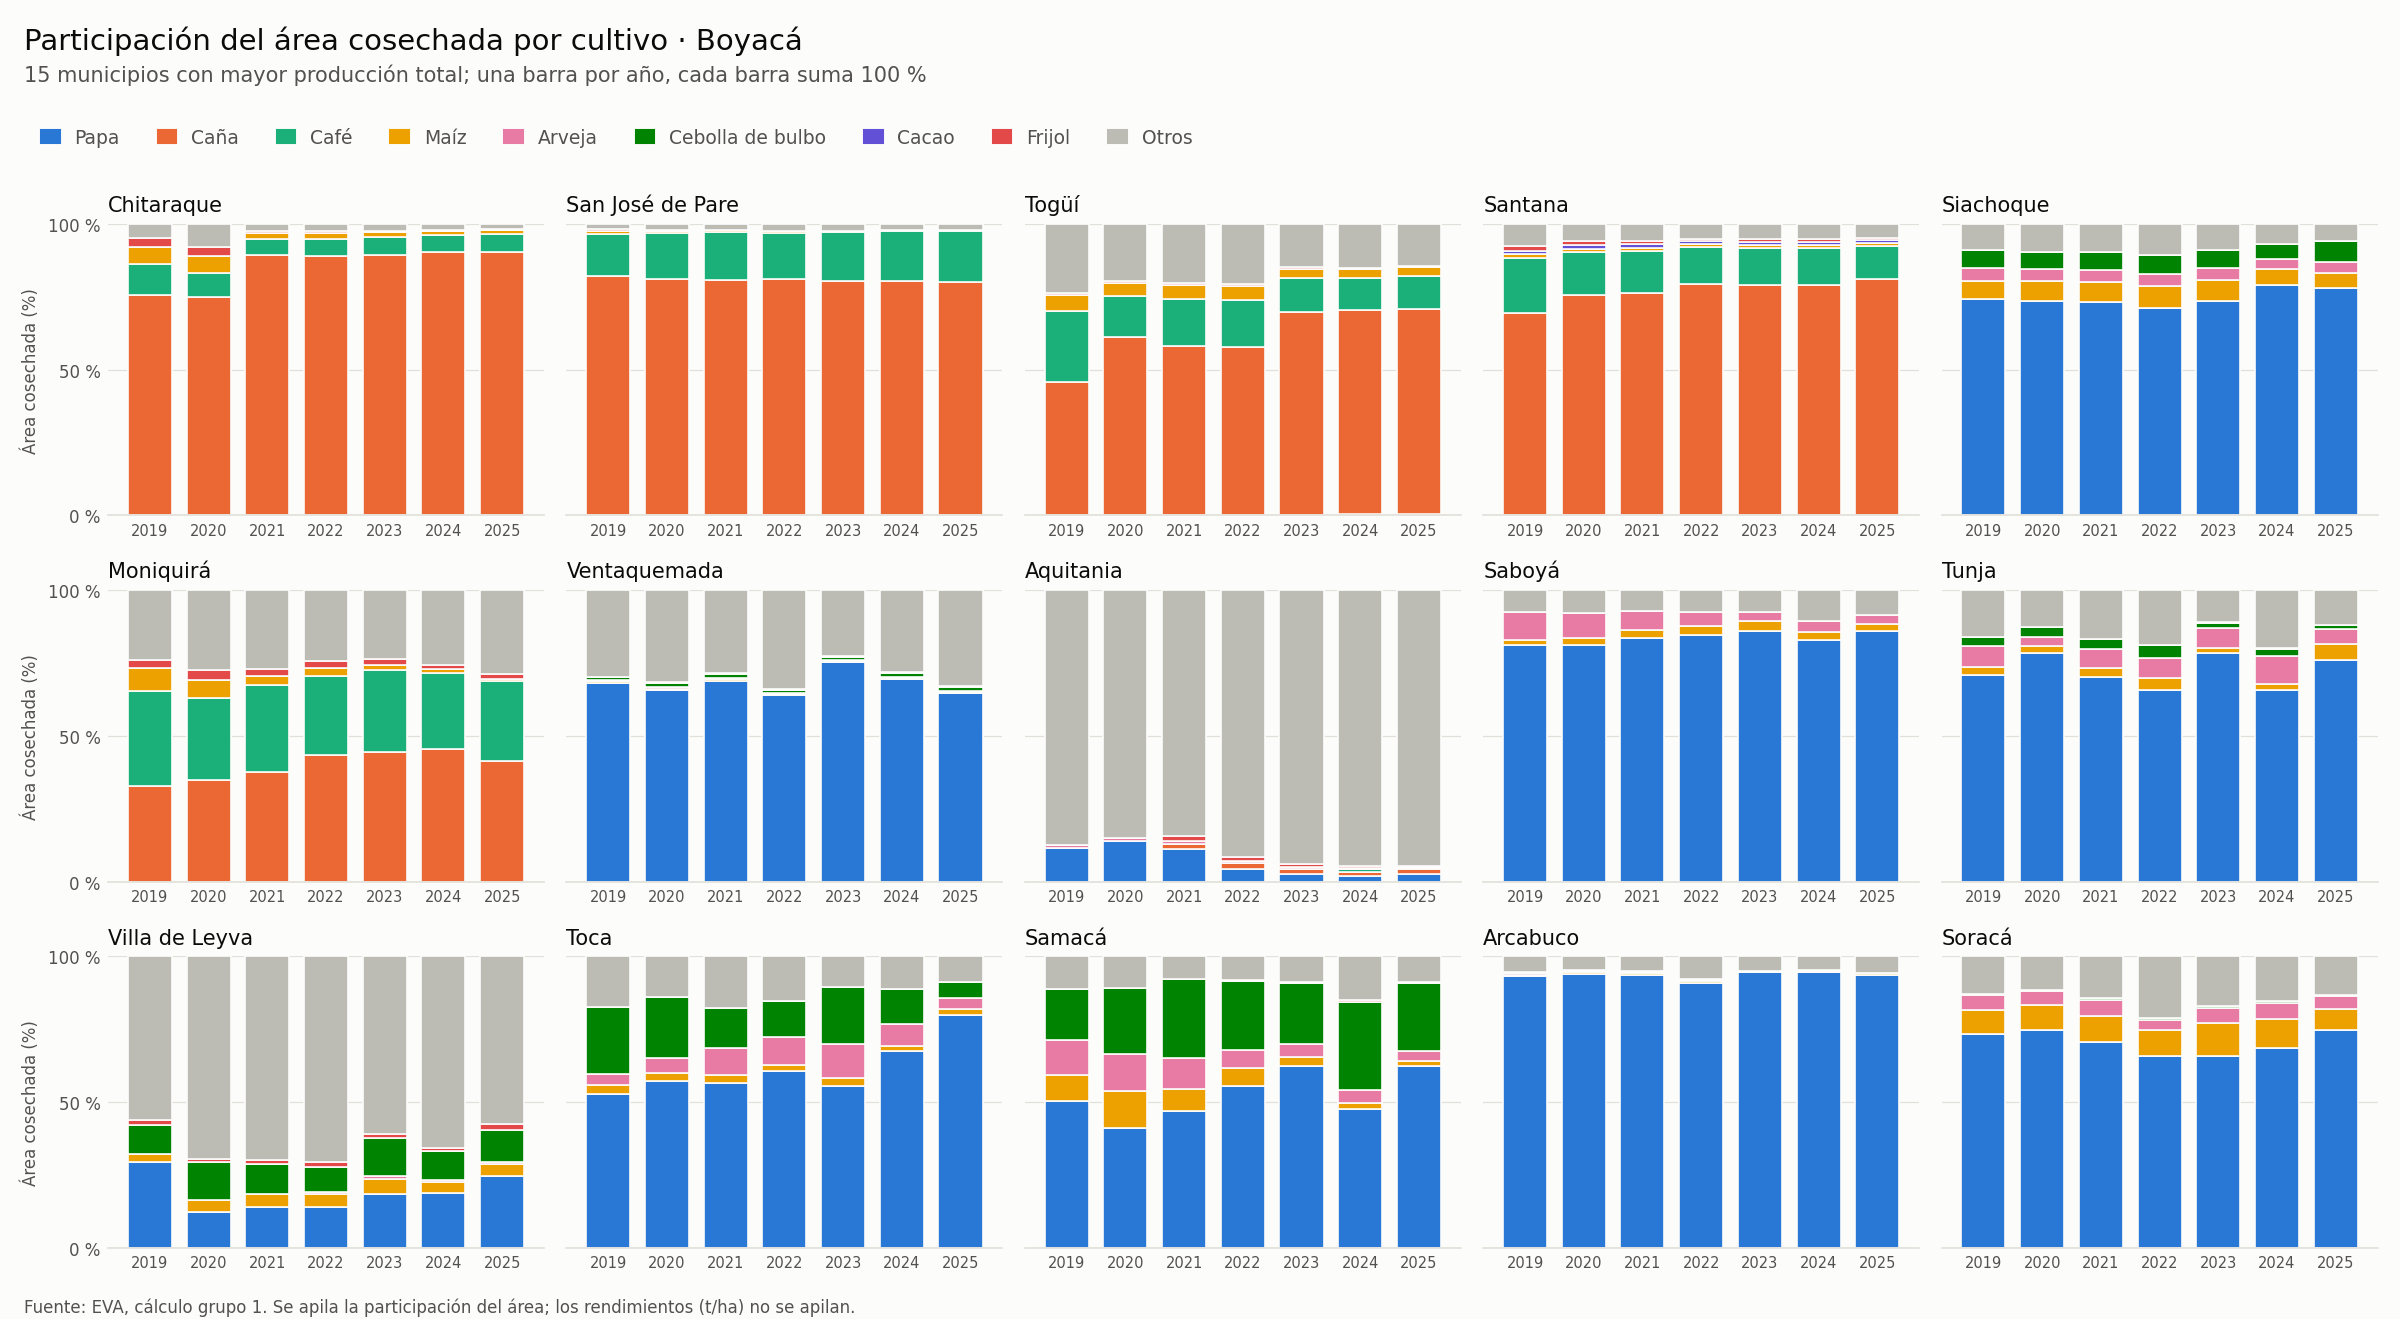

In [16]:
ruta_gold = REPOSITORIO / ejecucion_a['publicaciones']['gold']['ruta']
with conexion() as con:
    consulta_producto = con.execute(f"""
        SELECT municipio, anio, rank_municipio_anio, cultivo, estado_fisico,
               round(rendimiento_t_ha, 2) AS rendimiento_t_ha,
               round(rendimiento_nacional_t_ha, 2) AS rendimiento_nacional_t_ha,
               round(indice_relativo, 3) AS indice_relativo,
               area_cosechada_ha
        FROM {lectura_parquet(ruta_gold, 'rendimiento_cultivo')}
        WHERE codigo_municipio = '15001' AND anio = 2021 AND rank_municipio_anio <= 5
        ORDER BY rank_municipio_anio, cultivo
    """).df()
display(consulta_producto)

informe_a = presentacion_a['tablas']['informe_rendimiento']
print(f"Informe nacional: {len(informe_a):,} filas; "
      f"departamento {CONFIGURACION['departamento']}: "
      f"{informe_a['codigo_municipio'].str.startswith(CONFIGURACION['departamento']).sum():,} filas.")
display(Markdown(presentacion_a['archivos']['texto_resultados_limites.md']))
display(Image(data=presentacion_a['archivos']['barras_apiladas.png']))

### 5.6 Limpieza de memoria y caché

Paso del diagrama en SILVER. Las tablas de RAW y SILVER ya están publicadas y verificadas, y la comparación de la sección 7 usa sus firmas, así que se liberan. Se conservan GOLD y la presentación, que son pequeñas y se usan en la auditoría. La memoria se mide con `RssAnon`, que no cuenta los Parquet mapeados desde disco.

In [17]:
MEMORIA_ANTES = memoria_mb()
del raw_a, silver_a, caso_raw, silver_caso, tablas_caso
MEMORIA_DESPUES = liberar_memoria()
if MEMORIA_ANTES is None:
    print('Medición de memoria no disponible en este sistema (requiere /proc).')
else:
    print(f'Memoria de trabajo: {MEMORIA_ANTES:,.1f} MB → {MEMORIA_DESPUES:,.1f} MB '
          f'(liberados {MEMORIA_ANTES - MEMORIA_DESPUES:,.1f} MB)')

Memoria de trabajo: 569.0 MB → 483.7 MB (liberados 85.3 MB)


## 6. Registro de ejecución
Registra identificador, fuentes y huellas, reglas o versión del código, parámetros, versiones de bibliotecas, conteos, controles, estado, errores y salida válida. Identifica responsable de revisar incidencias.

Cada ejecución guarda `ejecuciones/<id>/registro.json` con:

- identificador, estado, producto, versiones del notebook y de las reglas, inicio y fin;
- parámetros y entradas: el manifiesto con huellas;
- por capa: estado, ruta, firma de entrada y de contenido, firmas por tabla, conteos y controles;
- controles de la consulta sobre lo publicado, errores, responsables y quién revisa incidencias: Brayan;
- el bloque `ENTORNO`.

Cada capa publicada agrega además una línea a `registro_publicaciones.jsonl`. Es el catálogo que usa la verificación de fuentes ya almacenadas, y solo se escribe después de que toda la ejecución supera sus controles. `publicacion_valida.json` indica qué ejecución y qué carpeta de cada capa son la publicación válida; se actualiza solo con una ejecución válida y conserva la anterior.

In [18]:
def registrar_ejecucion(ejecucion, etiqueta):
    carpeta = REPOSITORIO / ejecucion['carpeta']
    carpeta.mkdir(parents=True, exist_ok=True)
    registro = {
        'identificador': ejecucion['identificador'],
        'etiqueta': etiqueta,
        'estado': ejecucion['estado'],
        'producto': CONFIGURACION['producto'],
        'version_notebook': CONFIGURACION['version_notebook'],
        'version_reglas': CONFIGURACION['version_reglas'],
        'inicio': ejecucion['inicio'],
        'fin': ejecucion['fin'],
        'parametros': {'forzar': ejecucion['forzar'],
                       **{clave: CONFIGURACION[clave] for clave in
                          ['departamento', 'top_cultivos', 'municipios_grafico', 'cultivos_con_color',
                           'area_minima_hallazgos_ha', 'cifras_firma']}},
        'entradas': MANIFIESTO,
        'capas': ejecucion['publicaciones'],
        'controles_consulta': ejecucion['controles'],
        'errores': [],
        'responsables': CONFIGURACION['responsables'],
        'revisa_incidencias': CONFIGURACION['revisa_incidencias'],
        'entorno': ENTORNO,
    }
    escribir_json(carpeta / 'registro.json', registro)
    with REGISTRO.open('a', encoding='utf-8') as archivo:
        for capa in ejecucion['capas_nuevas']:
            p = ejecucion['publicaciones'][capa]
            archivo.write(json.dumps({
                'capa': capa, 'run_id': ejecucion['identificador'], 'fecha': ejecucion['fin'],
                'firma_entrada': p['firma_entrada'], 'firma_contenido': p['firma_contenido'], 'estado': 'valida',
                'ruta': p['ruta'], 'version_reglas': p['version_reglas'],
                'version_notebook': CONFIGURACION['version_notebook'], 'responsable': p['responsable'],
                'python': ENTORNO['python']['version'], 'commit': ENTORNO['git']['commit'],
            }, ensure_ascii=False) + '\n')
    return registro


def actualizar_publicacion(ejecucion, motivo):
    anterior = json.loads(PUBLICACION_RUTA.read_text(encoding='utf-8')) if PUBLICACION_RUTA.is_file() else None
    publicacion = {
        'ejecucion_valida': ejecucion['identificador'],
        'ejecucion_anterior': anterior['ejecucion_valida'] if anterior else None,
        'estado': 'VALIDA',
        'capas': {capa: p['ruta'] for capa, p in ejecucion['publicaciones'].items()},
        'actualizada': ahora(),
        'motivo': motivo,
    }
    escribir_json(PUBLICACION_RUTA, publicacion)
    return publicacion


registro_a = registrar_ejecucion(ejecucion_a, 'A')
publicacion = actualizar_publicacion(ejecucion_a, 'Ejecución A conciliada por grupo y total')

conteos_a = registro_a['capas']['raw']['conteos']
display(pd.DataFrame([{
    'identificador': registro_a['identificador'], 'estado': registro_a['estado'],
    'leidas': sum(c['leidas'] for c in conteos_a.values()),
    'aceptadas': sum(c['aceptadas'] for c in conteos_a.values()),
    'rechazadas': sum(c['rechazadas'] for c in conteos_a.values()),
    'filas_gold': registro_a['capas']['gold']['conteos']['filas_gold'],
    'controles': sum(len(p['controles']) for p in registro_a['capas'].values()),
}]))
print('Registro:', rel(REPOSITORIO / ejecucion_a['carpeta'] / 'registro.json'))
print('Publicación válida:', publicacion['ejecucion_valida'])

,identificador,estado,leidas,aceptadas,rechazadas,filas_gold,controles
0,5993e61ecfd3,VALIDA,260592,260590,2,107620,52


Registro: kit/salidas/grupo_1/E12/ejecuciones/5993e61ecfd3/registro.json
Publicación válida: 5993e61ecfd3


## 7. Reejecución y fallo controlado
Repite el recorrido con las mismas entradas y reglas en una carpeta B independiente. Compara contenido, claves y medidas de detalle, rechazados y agregado; los tiempos e identificadores pueden cambiar. Prueba un fallo de contrato sin alterar los originales y comprueba que no sustituye la publicación válida.

### 7.1 Ejecución B y comparación del contenido

B repite todo el recorrido desde los CSV con `forzar=True`, de modo que escribe en una carpeta nueva aunque la entrada ya esté publicada. Se compara con A capa por capa: la firma de contenido, la firma de cada tabla y los conteos. Identificadores, tiempos y bytes de los Parquet pueden cambiar; el contenido no. Si todo coincide, B pasa a ser la publicación válida y A queda como anterior.

In [19]:
resultados_b = calcular_capas(CRUDOS, MANIFIESTO)
ejecucion_b = publicar_ejecucion(resultados_b, HUELLAS, forzar=True)
registro_b = registrar_ejecucion(ejecucion_b, 'B')

filas = []
for capa in CAPAS:
    a, b = ejecucion_a['publicaciones'][capa], ejecucion_b['publicaciones'][capa]
    filas.append({
        'capa': capa,
        'ruta_a': a['ruta'], 'ruta_b': b['ruta'],
        'firma_contenido_igual': a['firma_contenido'] == b['firma_contenido'],
        'tablas_iguales': a['firmas'] == b['firmas'],
        'conteos_iguales': a['conteos'] == b['conteos'],
    })
comparacion = pd.DataFrame(filas).set_index('capa')
estable = bool(comparacion[['firma_contenido_igual', 'tablas_iguales', 'conteos_iguales']].all().all())
assert ejecucion_a['identificador'] != ejecucion_b['identificador']
assert estable, comparacion

escribir_json(SALIDA / 'comparacion_reejecuciones.json', {
    'ejecucion_a': ejecucion_a['identificador'], 'ejecucion_b': ejecucion_b['identificador'], 'estable': estable,
    'capas': comparacion.reset_index().to_dict('records'),
    'firmas_a': {c: p['firmas'] for c, p in ejecucion_a['publicaciones'].items()},
    'firmas_b': {c: p['firmas'] for c, p in ejecucion_b['publicaciones'].items()},
})
publicacion = actualizar_publicacion(
    ejecucion_b, 'Segunda ejecución estable y conciliada; se conserva la ejecución anterior')
display(comparacion)
print('Reejecución estable:', estable, '· publicación válida:', publicacion['ejecucion_valida'],
      '· anterior:', publicacion['ejecucion_anterior'])

,ruta_a,ruta_b,firma_contenido_igual,tablas_iguales,conteos_iguales
capa,,,,,
raw,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,True,True,True
silver,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,True,True,True
gold,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,True,True,True
presentacion,kit/salidas/grupo_1/E12/ejecuciones/5993e61ecf...,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,True,True,True


Reejecución estable: True · publicación válida: d0fbac228896 · anterior: 5993e61ecfd3


### 7.2 Verificación de fuentes ya almacenadas

Es el paso transversal del diagrama. Se vuelve a publicar con las mismas entradas y reglas, ahora con `forzar=False`. Todas las firmas de entrada ya están en el registro, así que ninguna capa se escribe de nuevo: se reutiliza la publicación de B y se comprueba que el contenido calculado tiene la misma firma.

In [20]:
ejecuciones_antes = sorted(p.name for p in (SALIDA / 'ejecuciones').iterdir())
ejecucion_c = publicar_ejecucion(resultados_b, HUELLAS, forzar=False)
ejecuciones_despues = sorted(p.name for p in (SALIDA / 'ejecuciones').iterdir())

assert ejecucion_c['estado'] == 'REUTILIZADA' and not ejecucion_c['capas_nuevas']
assert ejecuciones_antes == ejecuciones_despues
assert all(p['ruta'] == ejecucion_b['publicaciones'][capa]['ruta']
           for capa, p in ejecucion_c['publicaciones'].items())
display(resumen_publicaciones(ejecucion_c)[['estado', 'ruta', 'firma_contenido']])
print('Sin duplicados: ninguna capa se escribió de nuevo; se reutiliza la publicación de B.')

del resultados_b
print(f'Memoria de trabajo tras liberar la ejecución B: {liberar_memoria():,.1f} MB')

,estado,ruta,firma_contenido
capa,,,
raw,reutilizada,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,e6bbe0fb99e1…
silver,reutilizada,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,7205cafd4e70…
gold,reutilizada,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,222d889deb8d…
presentacion,reutilizada,kit/salidas/grupo_1/E12/ejecuciones/d0fbac2288...,277a950694e9…


Sin duplicados: ninguna capa se escribió de nuevo; se reutiliza la publicación de B.
Memoria de trabajo tras liberar la ejecución B: 585.9 MB


### 7.3 Fallo controlado de contrato

Se retira en memoria la columna obligatoria `Área cosechada` de EVA. El contrato de entrada de RAW debe detener el recorrido antes de publicar. Los CSV originales y `publicacion_valida.json` quedan intactos.

In [21]:
publicacion_antes = PUBLICACION_RUTA.read_text(encoding='utf-8')
crudos_defectuosos = {**CRUDOS, 'eva': CRUDOS['eva'].drop(columns=['Área cosechada'])}
try:
    calcular_capas(crudos_defectuosos, MANIFIESTO)
except ValueError as error:
    incidencia_controlada = {
        'estado': 'DETENIDA',
        'capa': 'raw',
        'causa_observada': str(error),
        'accion': 'No publicar; restaurar el archivo desde el original verificado y volver a ejecutar',
        'revisa': CONFIGURACION['revisa_incidencias'],
        'publicacion_conservada': json.loads(publicacion_antes)['ejecucion_valida'],
        'fecha': ahora(),
    }
else:
    raise AssertionError('El contrato debía detener la entrada sin la columna Área cosechada')

assert PUBLICACION_RUTA.read_text(encoding='utf-8') == publicacion_antes
assert all(sha256_archivo(DATOS / catalogo[fuente]['archivo']) == huella for fuente, huella in HUELLAS.items())
escribir_json(SALIDA / 'incidencia_contrato_controlada.json', incidencia_controlada)
del crudos_defectuosos
display(incidencia_controlada)

{'estado': 'DETENIDA',
 'capa': 'raw',
 'causa_observada': "Contrato incumplido en eva; faltantes=['Área cosechada']; extras=[]",
 'accion': 'No publicar; restaurar el archivo desde el original verificado y volver a ejecutar',
 'revisa': 'Brayan',
 'publicacion_conservada': 'd0fbac228896',
 'fecha': '2026-10-31T15:07:42-05:00'}

## 8. Auditoría entre equipos
Otro equipo reproduce una consulta y revisa los controles. Registra quién revisó, evidencia, hallazgo o control satisfactorio, acción y comprobación posterior. Explica una limitación de interpretación.

La tabla siguiente es la autoevaluación de los controles, con su evidencia, en el formato de la ficha de referencia del docente. La auditoría la hace **otro equipo** en la clínica del 6 de noviembre: reproduce la consulta de abajo desde la carpeta de la ejecución válida, compara con el resultado esperado y registra su nombre, evidencia, hallazgo, acción y comprobación posterior en `presentacion/ficha_auditoria.md`, sin inventar defectos.

In [22]:
conteos_b = registro_b['capas']['raw']['conteos']
conteos_silver_b = registro_b['capas']['silver']['conteos']
conteos_gold_b = registro_b['capas']['gold']['conteos']
ficha = pd.DataFrame([
    {'control': 'Entradas identificadas', 'estado': 'CUMPLE',
     'evidencia': 'Tres CSV con tamaño y SHA-256 iguales a kit/fuentes.json (manifiesto_entradas.json)',
     'accion': 'Ninguna'},
    {'control': 'Conteos conciliados', 'estado': 'CUMPLE',
     'evidencia': '; '.join(f"{f}: {cifra(c['leidas'], 0)} = {cifra(c['aceptadas'], 0)} + {cifra(c['rechazadas'], 0)}"
                            for f, c in conteos_b.items()),
     'accion': 'Ninguna'},
    {'control': 'Uniones sin multiplicar filas', 'estado': 'CUMPLE',
     'evidencia': f"unificado {cifra(conteos_silver_b['filas_unificado'], 0)} filas = EVA {cifra(conteos_silver_b['filas_eva_entrada'], 0)}; "
                  f"AGROSAVIA sin enlace: {cifra(conteos_silver_b['agrosavia_sin_enlace'], 0)} en sin_correspondencia",
     'accion': 'Revisar los alias pendientes con el grupo'},
    {'control': 'Agregado contra detalle', 'estado': 'CUMPLE',
     'evidencia': f"DuckDB sobre lo publicado: {cifra(conteos_gold_b['grupos_conciliados'], 0)} municipio-año y total cuadran",
     'accion': 'Ninguna'},
    {'control': 'Reejecución estable', 'estado': 'CUMPLE' if estable else 'NO CUMPLE',
     'evidencia': 'Firmas de contenido de las cuatro capas iguales entre A y B (comparacion_reejecuciones.json)',
     'accion': 'Ninguna'},
    {'control': 'Sin publicaciones duplicadas', 'estado': 'CUMPLE',
     'evidencia': 'Con forzar=False ninguna capa se escribió de nuevo (sección 7.2)', 'accion': 'Ninguna'},
    {'control': 'Fallo controlado', 'estado': 'CUMPLE',
     'evidencia': 'Sin Área cosechada el contrato detuvo RAW; la publicación válida no cambió',
     'accion': 'Ninguna'},
    {'control': 'Límite de interpretación', 'estado': 'CUMPLE',
     'evidencia': 'El índice relativo compara con el país; no indica causa ni aplica a fincas',
     'accion': 'Mantener el texto de límites junto al producto'},
])
ficha.to_csv(SALIDA / 'ficha_auditoria_grupo_1.csv', index=False)
display(ficha)
assert ficha['estado'].eq('CUMPLE').all()

ruta_valida = REPOSITORIO / publicacion['capas']['gold']
consulta_auditoria = (
    "SELECT municipio, anio, cultivo, estado_fisico, rendimiento_t_ha, indice_relativo\n"
    f"FROM {lectura_parquet('gold', 'rendimiento_cultivo')}\n"
    f"WHERE codigo_departamento = '{CONFIGURACION['departamento']}' AND rank_municipio_anio = 1\n"
    "ORDER BY municipio, anio, cultivo, estado_fisico"
)
with conexion() as con:
    esperado_auditoria = con.execute(
        consulta_auditoria.replace("'gold/", f"'{ruta_valida.as_posix()}/")).df()
print('Consulta para el equipo auditor (desde la carpeta de la ejecución válida):\n')
print(consulta_auditoria + ';')
print(f'\nResultado esperado: {len(esperado_auditoria)} filas. Primeras filas:')
display(esperado_auditoria.head().round(3))

,control,estado,evidencia,accion
0,Entradas identificadas,CUMPLE,Tres CSV con tamaño y SHA-256 iguales a kit/fu...,Ninguna
1,Conteos conciliados,CUMPLE,eva: 166.732 = 166.732 + 0; divipola: 1.122 = ...,Ninguna
2,Uniones sin multiplicar filas,CUMPLE,unificado 166.732 filas = EVA 166.732; AGROSAV...,Revisar los alias pendientes con el grupo
3,Agregado contra detalle,CUMPLE,DuckDB sobre lo publicado: 7.686 municipio-año...,Ninguna
4,Reejecución estable,CUMPLE,Firmas de contenido de las cuatro capas iguale...,Ninguna
5,Sin publicaciones duplicadas,CUMPLE,Con forzar=False ninguna capa se escribió de n...,Ninguna
6,Fallo controlado,CUMPLE,Sin Área cosechada el contrato detuvo RAW; la ...,Ninguna
7,Límite de interpretación,CUMPLE,El índice relativo compara con el país; no ind...,Mantener el texto de límites junto al producto


Consulta para el equipo auditor (desde la carpeta de la ejecución válida):

SELECT municipio, anio, cultivo, estado_fisico, rendimiento_t_ha, indice_relativo
FROM read_parquet('gold/rendimiento_cultivo.parquet')
WHERE codigo_departamento = '15' AND rank_municipio_anio = 1
ORDER BY municipio, anio, cultivo, estado_fisico;

Resultado esperado: 861 filas. Primeras filas:


,municipio,anio,cultivo,estado_fisico,rendimiento_t_ha,indice_relativo
0,ALMEIDA,2019,Lulo,En fresco,22.5,2.251
1,ALMEIDA,2020,Lulo,En fresco,25.0,2.494
2,ALMEIDA,2021,"Calabacín, calabaza",En fresco,60.0,3.036
3,ALMEIDA,2022,"Calabacín, calabaza",En fresco,60.0,3.743
4,ALMEIDA,2023,"Calabacín, calabaza",En fresco,60.0,3.759


**Ficha de auditoría:** la autoevaluación está en `kit/salidas/grupo_1/E12/ficha_auditoria_grupo_1.csv` y la plantilla para el equipo auditor en `presentacion/ficha_auditoria.md` de la ejecución válida. Faltan los campos que llena el otro equipo el 6 de noviembre: equipo auditor, fecha, resultado obtenido, hallazgo o control satisfactorio, acción y comprobación posterior. La limitación que se explicará: el índice relativo compara con el promedio nacional del mismo cultivo; no dice por qué un municipio rinde más ni aplica a una finca en particular.

## 9. Cierre y criterios de aceptación
Documenta evidencia para: ejecución completa; conteos conciliados; agregado consistente por grupo y total; y reejecución estable. Identifica pendientes y cómo regenerar las salidas. Entrega el notebook, manifiesto, consultas, registros de A y B y ficha de auditoría; las salidas voluminosas se entregan por el medio del curso y se excluyen de Git.

In [23]:
criterios_finales = {
    'ejecucion_completa': ejecucion_b['estado'] == 'VALIDA' and set(ejecucion_b['capas_nuevas']) == set(CAPAS),
    'conteos_explicables': all(c['leidas'] == c['aceptadas'] + c['rechazadas'] for c in conteos_b.values()),
    'agregado_consistente': all(ejecucion_b['controles'].values()),
    'reejecucion_estable': estable,
}
assert all(criterios_finales.values()), criterios_finales

carpeta_valida = REPOSITORIO / ejecucion_b['carpeta']
entregables = sorted(rel(ruta) for ruta in carpeta_valida.rglob('*') if ruta.is_file() and 'unificado' not in ruta.parts)
entregables += [rel(SALIDA / nombre) for nombre in [
    'manifiesto_entradas.json', 'registro_publicaciones.jsonl', 'publicacion_valida.json',
    'comparacion_reejecuciones.json', 'incidencia_contrato_controlada.json', 'ficha_auditoria_grupo_1.csv']]
resumen_final = {
    'criterios': criterios_finales,
    'publicacion_valida': publicacion,
    'conteos': {'raw': conteos_b, 'silver': conteos_silver_b, 'gold': conteos_gold_b},
    'controles_superados': sum(sum(p['controles'].values()) for p in ejecucion_b['publicaciones'].values()),
    'salida_relativa': rel(SALIDA),
    'entregables': entregables,
}
escribir_json(SALIDA / 'resumen_final.json', resumen_final)

display(pd.DataFrame([criterios_finales]))
display(tabla_controles(*[(capa, p) for capa, p in ejecucion_b['publicaciones'].items()]))
print(f"Particiones de unificado: {len(list((carpeta_valida / 'silver' / 'unificado').glob('*/*')))}")
print('Entregables:')
for ruta in entregables:
    print('  ', ruta)
print('\nPara regenerar: Kernel → Restart & Run All con los CSV de kit/data/raw/ (huellas en kit/fuentes.json).')

,ejecucion_completa,conteos_explicables,agregado_consistente,reejecucion_estable
0,True,True,True,True


,controles,superados
capa,,
raw,15,15
silver,16,16
gold,9,9
presentacion,12,12


Particiones de unificado: 224
Entregables:
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/entorno.json
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/gold/conciliacion.parquet
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/gold/consultas_gold.sql
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/gold/controles_gold.json
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/gold/rendimiento_cultivo.parquet
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/barras_apiladas.png
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/consultas_presentacion.sql
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/controles_presentacion.json
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/ficha_auditoria.md
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/informe_rendimiento.csv
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac228896/presentacion/informe_rendimiento.md
   kit/salidas/grupo_1/E12/ejecuciones/d0fbac

**Conclusiones y pendientes:**

- Los cuatro criterios de aceptación se cumplen con datos completos: ejecución completa, conteos explicables, agregado consistente por grupo y total, y reejecución estable. Las cifras están en las salidas de las secciones 5 a 9 y en `resumen_final.json`.
- El notebook integrado sustituye a los cuatro notebooks por capa, que quedan en `soluciones/grupo_1/` como antecedentes de cada integrante. Se unificaron:
  - una sola definición de rutas, entorno, huella, firma, contrato, registro y antiduplicidad;
  - una firma de contenido que no depende del contrato de cada tabla, encadenada de capa en capa;
  - un solo registro de publicaciones.
- Cambios de reglas frente a los notebooks por capa:
  - **GOLD** (`g1-gold-v2`): la conciliación usa `FULL OUTER JOIN`, y `consultas_gold.sql` usa rutas relativas e incluye la vista de carga.
  - **Presentación** (`g1-presentacion-v2`): el gráfico usa un panel por municipio, porque con siete años y quince municipios una sola fila de barras no se lee. Los hallazgos se calculan; antes había una cifra escrita a mano («más del 70 %»). El control de producción usa `produccion_total_t`, el nombre del contrato GOLD.
- Pendientes:
  - Auditoría cruzada con otro equipo el 6 de noviembre, completando la ficha.
  - `soluciones/plan_grupo_1/fixtures/gold/` contiene datos simulados que generó el notebook de presentación; conviene reemplazarlos por la salida GOLD del fixture.
  - Ampliación opcional: reconstruir un período afectado y comprobar que los demás no cambian.